# Análise dos resultados — Trabalho 1 de Redes

Notebook baseado nas seções 4, 6–9 do [guia revisado](../docs/GUIA_COMPLETO_TRABALHO1_REDES.md), no [contrato implementado](../docs/CONTRATO_PROTOCOLO.md) e na [matriz versionada](../configs/experiment_plan.csv).

Execute as células em ordem, com o Python de `.venv-analysis` selecionado no Jupyter/VS Code. Instalação: `python -m pip install -r analysis/requirements-notebook.txt`, a partir da raiz. Antes da execução, tente o inventário `all` e aprove o perfil `analysis`, conforme [AMBIENTE.md](../docs/AMBIENTE.md). Este notebook não executa tráfego nem altera os dados brutos. A exportação final é opcional.

**Escopo da evidência:** os registros de campanha são analisados como encontrados; a existência dos JSONs não comprova sozinha a calibração CORE. Falhas, ausências e integridade não verificada aparecem explicitamente. HEAD é extensão do grupo e não transfere conteúdo. A rodada, e não cada worker concorrente, é a unidade dos ICs.

Verificação remota realizada em 05/11/2026: `git ls-remote origin` retornou `2ba1776dc8331c80a1eb91f3bd33f5f7ed8987ed` para HEAD e `refs/heads/main`, igual ao HEAD local. A consulta não fez merge, pull ou push. Reexecute a consulta para verificar mudanças posteriores.

In [1]:
from pathlib import Path
import hashlib
import json
import platform
import subprocess
import importlib.metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import t
from IPython.display import display, Markdown

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / 'configs/experiment_plan.csv').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('Abra o notebook dentro do repositório.')
# Uma única campanha: backups e raw-final não são concatenados à campanha ativa.
RAW = ROOT / 'experiments/raw'
EXPORTAR = False
SAIDA = ROOT / 'experiments/summary/notebook'
PLAN = pd.read_csv(ROOT / 'configs/experiment_plan.csv')
FACTORS = ['profile', 'bandwidth_mbps', 'delay_oneway_ms', 'operation',
           'workload', 'file_size_bytes', 'concurrency']
ROUND = ['scenario_id', 'repetition']
assert not PLAN.scenario_id.duplicated().any(), 'IDs duplicados na matriz'
assert not PLAN.duplicated(FACTORS).any(), 'Células duplicadas na matriz'
pd.set_option('display.max_rows', 40)
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': .25})
print('Python:', platform.python_version())
print({m: importlib.metadata.version(m) for m in ['numpy', 'pandas', 'scipy', 'matplotlib']})
print('Campanha:', RAW.relative_to(ROOT))
print('HEAD atual:', subprocess.check_output(['git', 'rev-parse', 'HEAD'], cwd=ROOT, text=True).strip())

Python: 3.14.4
{'numpy': '2.5.4', 'pandas': '3.1.1', 'scipy': '1.18.1', 'matplotlib': '3.11.2'}
Campanha: experiments/raw
HEAD atual: 2ba1776dc8331c80a1eb91f3bd33f5f7ed8987ed


## Origem e consistência

A leitura parte dos JSONs originais, sem usar as estatísticas antigas como entrada. O manifesto SHA-256 registra exatamente quais arquivos foram lidos. Divergências de fatores, IDs ou workers interrompem a execução para evitar misturar cenários. Um JSON malformado também interrompe a leitura, sem ser descartado silenciosamente.

In [2]:
records, provenance = [], []
files = sorted((RAW / 'json').glob('S*.json'))
if not files:
    raise FileNotFoundError(f'Nenhum resultado em {RAW / "json"}')
for path in files:
    content = path.read_bytes()
    d = json.loads(content)
    c = d['client_result']
    records.append({**{k: v for k, v in d.items() if k not in ['client_result', 'command']},
                    'operation': c.get('method'), 'status': c.get('status'),
                    'status_code': c.get('status_code'), 'bytes': c.get('bytes'),
                    'elapsed_ms': c.get('elapsed_ms'), 'reported_mbps': c.get('throughput_mbps'),
                    'error': c.get('error'), 'source': str(path.relative_to(ROOT))})
    provenance.append({'path': str(path.relative_to(ROOT)),
                       'sha256': hashlib.sha256(content).hexdigest()})
req = pd.DataFrame(records)
manifest = pd.DataFrame(provenance)
assert not req.duplicated(ROUND + ['worker']).any(), 'Worker duplicado'
assert not req.identifier.duplicated().any(), 'Identificador duplicado'
assert set(req.scenario_id) <= set(PLAN.scenario_id), 'Cenário fora da matriz'
for k in FACTORS:
    expected = req.scenario_id.map(PLAN.set_index('scenario_id')[k])
    assert req[k].eq(expected).all(), f'Fator divergente: {k}'
for field in ['repetition', 'worker', 'client_exit_code', 'status_code', 'bytes', 'elapsed_ms', 'reported_mbps']:
    req[field] = pd.to_numeric(req[field], errors='raise')
for (sid, rep), g in req.groupby(ROUND):
    plan = PLAN.set_index('scenario_id').loc[sid]
    assert rep == int(rep) and 1 <= rep <= plan.repetitions, f'Rodada inesperada: {sid}/{rep}'
    assert g.worker.isin(range(1, int(plan.concurrency) + 1)).all(), f'Worker inválido: {sid}/{rep}'
# O CSV consolidado anterior é apenas uma conferência de procedência.
cache_path = ROOT / 'analysis/data/individual.csv'
if cache_path.exists():
    cached = pd.read_csv(cache_path)
    print('CSV anterior: linhas =', len(cached), '; mesmos IDs =', set(cached.identifier) == set(req.identifier))
print(f'{len(req):,} registros; {len(req.groupby(ROUND))} rodadas observadas; {req.scenario_id.nunique()} células.')
display(req[['scenario_id', 'repetition', 'worker', 'operation', 'elapsed_ms', 'bytes']].head())

CSV anterior: linhas = 5412 ; mesmos IDs = True
5,412 registros; 396 rodadas observadas; 36 células.


,scenario_id,repetition,worker,operation,elapsed_ms,bytes
0,S001,1,1,GET,249.086,2097152
1,S001,2,1,GET,242.959,2097152
2,S001,3,1,GET,239.696,2097152
3,S001,4,1,GET,238.426,2097152
4,S001,5,1,GET,245.118,2097152


In [3]:
# Avalia evidência preservada de hashes, sem alegar re-hash de arquivos ausentes.
def hash_evidence(identifier, operation):
    if operation == 'HEAD':
        return 'não aplicável'
    path = RAW / 'hashes' / f'{identifier}.sha256'
    if not path.exists():
        return 'sem evidência'
    hashes = {}
    for line in path.read_text(encoding='utf-8').splitlines():
        parts = line.split(maxsplit=2)
        if len(parts) == 3:
            hashes[parts[0]] = parts[1]
    if operation == 'GET' and 'input' in hashes and 'output' in hashes:
        return 'conferido no registro' if hashes['input'] == hashes['output'] else 'divergente'
    # input sozinho não verifica o conteúdo publicado no servidor pelo PUT.
    return 'destino não verificado'

req['hash_evidence'] = [hash_evidence(i, op) for i, op in zip(req.identifier, req.operation)]
head = req.operation.eq('HEAD')
expected_bytes = np.where(head, 0, req.file_size_bytes)
req['telemetry_ok'] = (
    req.status.eq('ok') & req.client_exit_code.eq(0) & req.status_code.between(200, 299)
    & req.bytes.eq(expected_bytes) & np.isfinite(req.elapsed_ms) & req.elapsed_ms.gt(0)
    & req.error.fillna('').eq(''))
if 'collector_error' in req:
    req['telemetry_ok'] &= req.collector_error.fillna('').eq('')
req['valid'] = req.telemetry_ok & req.hash_evidence.ne('divergente')
req['individual_mbps'] = np.where(req.valid & ~head, req.bytes * .008 / req.elapsed_ms, np.nan)
req['rate_matches'] = np.isclose(req.reported_mbps, req.individual_mbps, atol=.001, rtol=.0001) | head | ~req.valid
print('Taxas reportadas divergentes da fórmula:', int((~req.rate_matches).sum()))
print('HEAD com vazão indevida:', int((head & req.reported_mbps.notna()).sum()))
display(pd.crosstab(req.operation, req.hash_evidence))
display(req.groupby(['profile', 'operation', 'status', 'status_code'], dropna=False).size().rename('tentativas').reset_index())

Taxas reportadas divergentes da fórmula: 0
HEAD com vazão indevida: 0


hash_evidence,conferido no registro,destino não verificado,não aplicável
operation,,,
GET,1804,0,0
HEAD,0,0,1804
PUT,0,1804,0


,profile,operation,status,status_code,tentativas
0,A,GET,ok,200,902
1,A,HEAD,ok,200,902
2,A,PUT,ok,201,902
3,B,GET,ok,200,902
4,B,HEAD,ok,200,902
5,B,PUT,ok,201,902


## Cobertura, falhas e rodadas

Tempo em ms; arquivo em MiB (2²⁰ bytes); vazão útil em Mbit/s (10⁶ bits/s). A fórmula individual é `bytes × 8 / (elapsed_ms / 1000) / 10⁶`. Desempenho é condicionado às rodadas completas e sem falha detectada; o quadro de cobertura mantém também as ausentes, parciais e falhas. Sucesso de telemetria não equivale a integridade comprovada do PUT: os arquivos `.sha256` do coletor guardam apenas o hash da entrada para esse método.

In [4]:
rows = []
for (sid, rep), g in req.groupby(ROUND):
    p = PLAN.set_index('scenario_id').loc[sid]
    good = g.loc[g.valid]
    complete = len(g) == int(p.concurrency) and len(good) == len(g)
    rows.append({'scenario_id': sid, 'repetition': rep, **{k: p[k] for k in FACTORS},
                 'observed': len(g), 'successes': len(good), 'failures': len(g) - len(good),
                 'missing_workers': int(p.concurrency) - len(g), 'complete': complete,
                 'response_ms': good.elapsed_ms.mean() if complete else np.nan,
                 'individual_mbps': good.individual_mbps.mean() if complete and p.operation != 'HEAD' else np.nan,
                 'sum_individual_mbps': good.individual_mbps.sum() if complete and p.operation != 'HEAD' else np.nan,
                 # Não há timestamps monotônicos inicial/final comuns no schema atual.
                 'aggregate_mbps': np.nan})
rounds = pd.DataFrame(rows)
coverage = rounds.groupby('scenario_id').agg(
    observed_rounds=('repetition', 'size'), complete_rounds=('complete', 'sum'),
    observed_requests=('observed', 'sum'), successes=('successes', 'sum'), failures=('failures', 'sum'))
coverage = PLAN.merge(coverage, on='scenario_id', how='left').fillna(
    {k: 0 for k in coverage.columns})
coverage['expected_requests'] = coverage.concurrency * coverage.repetitions
coverage['missing_requests'] = coverage.expected_requests - coverage.observed_requests
coverage['excluded_or_absent_rounds'] = coverage.repetitions - coverage.complete_rounds
coverage['observed_success_pct'] = 100 * coverage.successes / coverage.observed_requests.replace(0, np.nan)
coverage['planned_success_pct'] = 100 * coverage.successes / coverage.expected_requests
coverage['enough_rounds'] = coverage.complete_rounds.ge(coverage.repetitions) & coverage.complete_rounds.ge(11)
display(coverage[['scenario_id', 'profile', 'operation', 'concurrency', 'observed_rounds', 'complete_rounds',
                  'excluded_or_absent_rounds', 'failures', 'missing_requests', 'observed_success_pct', 'enough_rounds']])
failures = req.loc[~req.valid, ['identifier', 'status', 'status_code', 'error', 'hash_evidence']]
print('Falhas detectadas:', len(failures), '; requisições ausentes:', int(coverage.missing_requests.sum()))
if not failures.empty:
    display(failures)

,scenario_id,profile,operation,concurrency,observed_rounds,complete_rounds,excluded_or_absent_rounds,failures,missing_requests,observed_success_pct,enough_rounds
0,S001,A,GET,1,11,11,0,0,0,100.0,True
1,S002,A,GET,8,11,11,0,0,0,100.0,True
2,S003,A,GET,32,11,11,0,0,0,100.0,True
3,S004,A,GET,1,11,11,0,0,0,100.0,True
4,S005,A,GET,8,11,11,0,0,0,100.0,True
5,S006,A,GET,32,11,11,0,0,0,100.0,True
6,S007,A,PUT,1,11,11,0,0,0,100.0,True
7,S008,A,PUT,8,11,11,0,0,0,100.0,True
8,S009,A,PUT,32,11,11,0,0,0,100.0,True
9,S010,A,PUT,1,11,11,0,0,0,100.0,True


Falhas detectadas: 0 ; requisições ausentes: 0


In [5]:
# IC95% de Student entre médias de rodadas; nenhum IC entre workers é utilizado.
def describe_rounds(values):
    x = np.asarray(pd.Series(values).dropna(), dtype=float)
    assert np.isfinite(x).all(), 'Métrica não finita'
    n = len(x)
    mean = x.mean() if n else np.nan
    sd = x.std(ddof=1) if n > 1 else np.nan
    half = t.ppf(.975, n - 1) * sd / np.sqrt(n) if n > 1 else np.nan
    return dict(n=n, mean=mean, median=np.median(x) if n else np.nan,
                std=sd, ci95_low=mean-half, ci95_high=mean+half, half=half)

stats = []
for _, p in PLAN.iterrows():
    g = rounds.loc[rounds.scenario_id.eq(p.scenario_id) & rounds.complete]
    for metric in ['response_ms', 'individual_mbps', 'aggregate_mbps']:
        stats.append({**p.to_dict(), 'metric': metric, **describe_rounds(g[metric])})
summary = pd.DataFrame(stats)
summary['size_mib'] = summary.file_size_bytes / 2**20
display(summary.loc[summary.metric.eq('response_ms'),
                    ['scenario_id', 'profile', 'operation', 'size_mib', 'concurrency', 'n', 'mean', 'median', 'std', 'ci95_low', 'ci95_high']].round(3))
print('IC aproximado: pressupõe independência suficiente entre rodadas. n=0 indica métrica não disponível/aplicável.')

,scenario_id,profile,operation,size_mib,concurrency,n,mean,median,std,ci95_low,ci95_high
0,S001,A,GET,2.0,1,11,242.194,241.923,3.561,239.802,244.586
3,S002,A,GET,2.0,8,11,1319.418,1339.819,44.391,1289.596,1349.240
6,S003,A,GET,2.0,32,11,5101.817,5115.795,54.582,5065.149,5138.486
9,S004,A,GET,10.0,1,11,960.836,955.275,14.053,951.395,970.277
12,S005,A,GET,10.0,8,11,6729.115,6686.657,133.049,6639.731,6818.499
15,S006,A,GET,10.0,32,11,28105.378,27994.400,1004.836,27430.320,28780.436
18,S007,A,PUT,2.0,1,11,237.658,235.319,3.566,235.262,240.054
21,S008,A,PUT,2.0,8,11,1392.808,1353.932,99.556,1325.925,1459.691
24,S009,A,PUT,2.0,32,11,5455.076,5380.451,276.684,5269.197,5640.954
27,S010,A,PUT,10.0,1,11,1171.918,962.046,444.043,873.605,1470.230


IC aproximado: pressupõe independência suficiente entre rodadas. n=0 indica métrica não disponível/aplicável.


## Comparações controladas e distribuições

Cada painel fixa perfil, método e tamanho; as linhas variam somente o tamanho, identificado na legenda. As barras representam IC95% de Student entre rodadas. A média da vazão individual é uma média de taxas, não a taxa obtida a partir do tempo médio. Boxplots usam médias por rodada; a CDF individual é descritiva e não amplia o n dos ICs. Não removemos outliers.

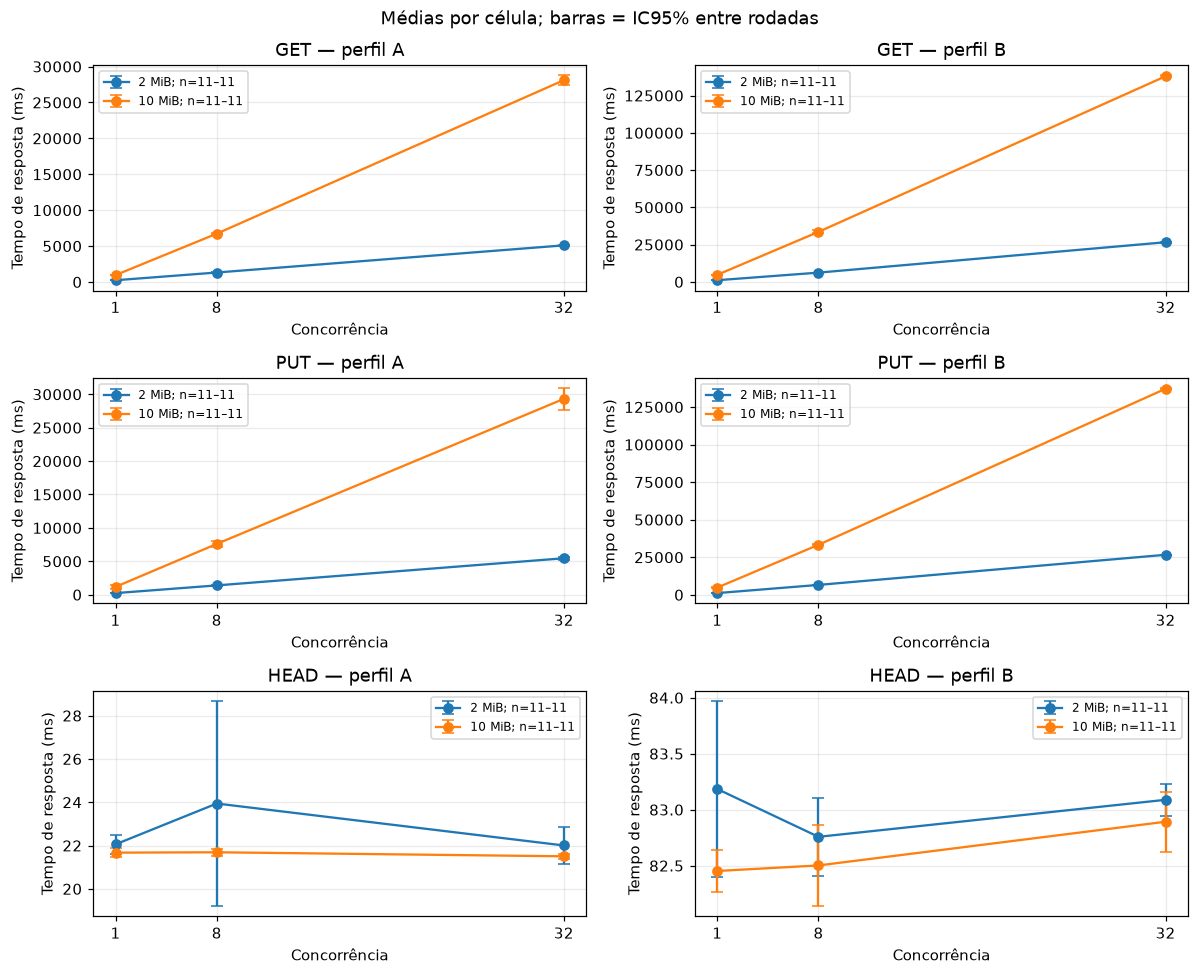

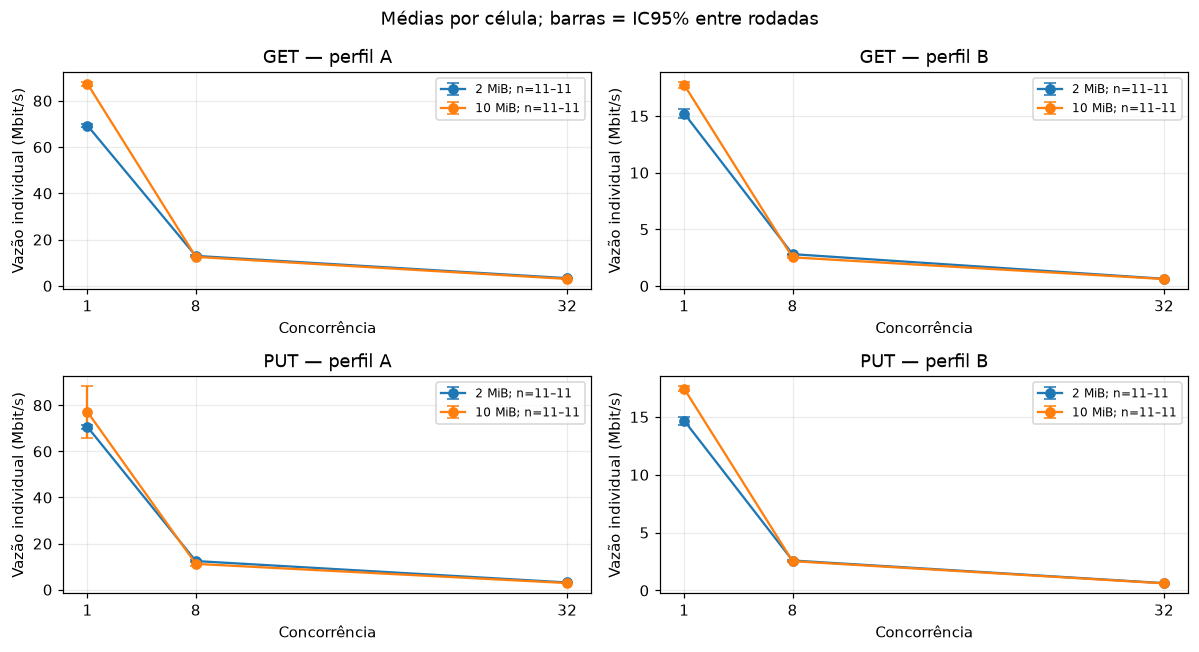

In [6]:
figures = {}
def metric_plot(metric, ylabel, operations, name):
    fig, axes = plt.subplots(len(operations), 2, figsize=(11, 3 * len(operations)), squeeze=False)
    for i, op in enumerate(operations):
        for j, profile in enumerate(['A', 'B']):
            ax = axes[i, j]
            part = summary.loc[summary.metric.eq(metric) & summary.operation.eq(op) & summary.profile.eq(profile)]
            for size, g in part.groupby('size_mib'):
                g = g.sort_values('concurrency')
                ax.errorbar(g.concurrency, g['mean'], yerr=g.half, marker='o', capsize=4,
                            label=f'{size:g} MiB; n={g.n.min()}–{g.n.max()}')
            ax.set(title=f'{op} — perfil {profile}', xlabel='Concorrência', ylabel=ylabel, xticks=[1, 8, 32])
            ax.legend(fontsize=8)
    fig.suptitle('Médias por célula; barras = IC95% entre rodadas')
    fig.tight_layout()
    figures[name] = fig
    plt.show()
metric_plot('response_ms', 'Tempo de resposta (ms)', ['GET', 'PUT', 'HEAD'], 'tempo')
metric_plot('individual_mbps', 'Vazão individual (Mbit/s)', ['GET', 'PUT'], 'vazao_individual')

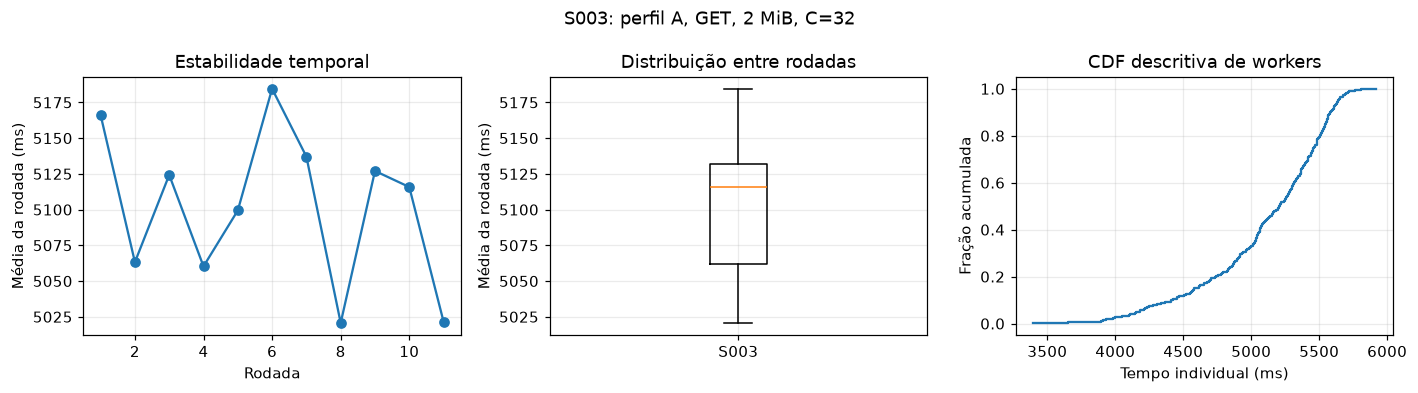

In [7]:
# Inspecione uma célula por vez sem reunir perfis ou concorrências.
SCENARIO = 'S003'
selected = req.loc[req.scenario_id.eq(SCENARIO)]
p = PLAN.set_index('scenario_id').loc[SCENARIO]
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
g = rounds.loc[rounds.scenario_id.eq(SCENARIO) & rounds.complete]
axes[0].plot(g.repetition, g.response_ms, 'o-')
axes[0].set(xlabel='Rodada', ylabel='Média da rodada (ms)', title='Estabilidade temporal')
axes[1].boxplot(g.response_ms.dropna().to_numpy(), tick_labels=[SCENARIO])
axes[1].set(ylabel='Média da rodada (ms)', title='Distribuição entre rodadas')
x = np.sort(selected.loc[selected.valid, 'elapsed_ms'])
if len(x):
    axes[2].step(x, np.arange(1, len(x)+1)/len(x), where='post')
axes[2].set(xlabel='Tempo individual (ms)', ylabel='Fração acumulada', title='CDF descritiva de workers')
fig.suptitle(f'{SCENARIO}: perfil {p.profile}, {p.operation}, {p.file_size_bytes / 2**20:g} MiB, C={p.concurrency}')
fig.tight_layout()
figures['distribuicao'] = fig
plt.show()

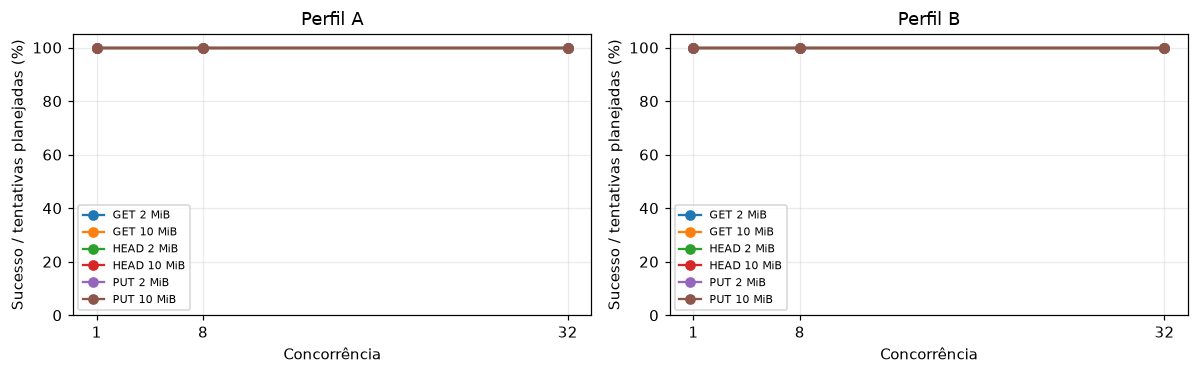

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for ax, profile in zip(axes, ['A', 'B']):
    part = coverage.loc[coverage.profile.eq(profile)]
    for (op, size), g in part.groupby(['operation', 'file_size_bytes']):
        g = g.sort_values('concurrency')
        ax.plot(g.concurrency, g.planned_success_pct, 'o-', label=f'{op} {size / 2**20:g} MiB')
    ax.set(title=f'Perfil {profile}', xlabel='Concorrência', ylabel='Sucesso / tentativas planejadas (%)',
           xticks=[1, 8, 32], ylim=(0, 105))
    ax.legend(fontsize=7)
fig.tight_layout()
figures['sucesso'] = fig
plt.show()

In [9]:
# A/B mantêm método, tamanho e concorrência iguais. Razões descritivas, sem IC pareado.
s = summary.loc[summary.metric.isin(['response_ms', 'individual_mbps'])]
comparison = s.pivot(index=['operation', 'file_size_bytes', 'concurrency', 'metric'], columns='profile', values='mean').reset_index()
comparison['B_div_A'] = comparison.B / comparison.A
comparison['size_mib'] = comparison.file_size_bytes / 2**20
display(comparison[['operation', 'size_mib', 'concurrency', 'metric', 'A', 'B', 'B_div_A']].round(3))
# Efeito C=32 versus C=1 sem reunir métodos/tamanhos/perfis.
concurrency_effect = s.pivot(index=['profile', 'operation', 'file_size_bytes', 'metric'], columns='concurrency', values='mean').reset_index()
concurrency_effect['C32_div_C1'] = concurrency_effect[32] / concurrency_effect[1]
display(concurrency_effect.round(3))

profile,operation,size_mib,concurrency,metric,A,B,B_div_A
0,GET,2.0,1,individual_mbps,69.285,15.217,0.220
1,GET,2.0,1,response_ms,242.194,1104.322,4.560
2,GET,2.0,8,individual_mbps,12.946,2.806,0.217
3,GET,2.0,8,response_ms,1319.418,6200.935,4.700
4,GET,2.0,32,individual_mbps,3.318,0.634,0.191
5,GET,2.0,32,response_ms,5101.817,26589.954,5.212
6,GET,10.0,1,individual_mbps,87.322,17.744,0.203
7,GET,10.0,1,response_ms,960.836,4729.790,4.923
8,GET,10.0,8,individual_mbps,12.539,2.525,0.201
9,GET,10.0,8,response_ms,6729.115,33544.419,4.985


concurrency,profile,operation,file_size_bytes,metric,1,8,32,C32_div_C1
0,A,GET,2097152,individual_mbps,69.285,12.946,3.318,0.048
1,A,GET,2097152,response_ms,242.194,1319.418,5101.817,21.065
2,A,GET,10485760,individual_mbps,87.322,12.539,2.997,0.034
3,A,GET,10485760,response_ms,960.836,6729.115,28105.378,29.251
4,A,HEAD,2097152,individual_mbps,NaN,NaN,NaN,NaN
5,A,HEAD,2097152,response_ms,22.055,23.941,22.004,0.998
6,A,HEAD,10485760,individual_mbps,NaN,NaN,NaN,NaN
7,A,HEAD,10485760,response_ms,21.672,21.690,21.503,0.992
8,A,PUT,2097152,individual_mbps,70.608,12.434,3.131,0.044
9,A,PUT,2097152,response_ms,237.658,1392.808,5455.076,22.953


## Vazão agregada, calibração e limites de inferência

A análise antiga (`scripts/analyze_results.py`) calcula `throughput_aggregate_mbps` somando taxas individuais. Isso não mede bytes totais por janela comum quando os clientes têm inícios/durações diferentes e pode até ultrapassar a capacidade nominal. Esse valor não é usado como goodput agregado neste notebook.

O coletor atual grava `started_utc` **depois** do subprocesso, e não preserva seus instantes monotônicos inicial/final ou uma janela da rodada. Não é possível recuperar rigorosamente essa janela a partir desses registros. `aggregate_mbps` permanece ausente; nem soma de taxas nem `C × tamanho / maior tempo individual` substituem uma janela medida. Para nova coleta: preservar início antes da liberação, término do último cliente, desvio de lançamento, bytes confirmados e hashes de destino de GET/PUT fora da medição. Então calcular `soma(bytes confirmados) × 8 / janela_s / 10⁶`.

Compare esse goodput com iperf3 no mesmo sentido: GET usa servidor→cliente; PUT usa cliente→servidor. Sem janela e calibração preservadas, queda da taxa individual e aumento da latência sustentam compartilhamento/contenda, mas não determinam isoladamente um ponto de saturação do enlace. CPU, disco, filas, cache, TCP e overhead do host CORE também podem limitar o sistema. Os perfis A/B alteram capacidade **e** atraso: a comparação não identifica o efeito isolado de cada fator.

In [10]:
# Inventário de evidências: existência de arquivo não equivale a validação de conteúdo.
checks = []
for profile in ['A', 'B']:
    folder = ROOT / 'experiments/calibration' / profile
    for name in ['ping.txt', 'traceroute.txt', 'iperf-get.json', 'iperf-put.json']:
        path = folder / name
        checks.append({'profile': profile, 'evidence': name, 'exists': path.is_file(),
                       'nonempty': path.is_file() and path.stat().st_size > 0})
calibration = pd.DataFrame(checks)
display(calibration)
print('Outros arquivos preservados em calibration:',
      [str(p.relative_to(ROOT)) for p in (ROOT / 'experiments/calibration').rglob('*') if p.is_file()])
print('Sessões CORE:', [str(p.relative_to(ROOT)) for p in (ROOT / 'topology').glob('*.xml')])
print('Vazão agregada com janela medida disponível:', rounds.aggregate_mbps.notna().any())

,profile,evidence,exists,nonempty
0,A,ping.txt,False,False
1,A,traceroute.txt,False,False
2,A,iperf-get.json,False,False
3,A,iperf-put.json,False,False
4,B,ping.txt,False,False
5,B,traceroute.txt,False,False
6,B,iperf-get.json,False,False
7,B,iperf-put.json,False,False


Outros arquivos preservados em calibration: ['experiments/calibration/.gitkeep', 'experiments/calibration/topologia-etapa4.txt', 'experiments/calibration/topologia-perfil-B.txt']
Sessões CORE: ['topology/trabalho1-etapa4-perfil-A.xml', 'topology/trabalho1-etapa4-perfil-B.xml', 'topology/trabalho1-etapa4.xml']
Vazão agregada com janela medida disponível: False


In [11]:
# Síntese gerada dos dados, sem copiar conclusões dos relatórios anteriores.
lat = comparison.loc[comparison.metric.eq('response_ms')]
rate = comparison.loc[comparison.metric.eq('individual_mbps') & comparison.operation.ne('HEAD')]
text = [
    f'**Resultados observados:** {len(req):,} requisições, {len(rounds)} rodadas e {req.scenario_id.nunique()} células.',
    f'{int(req.valid.sum()):,} registros passaram nos critérios de telemetria e ausência de hash divergente; '
    f'{len(failures)} falhas detectadas e {int(coverage.missing_requests.sum())} requisições ausentes.',
    f'{int(coverage.enough_rounds.sum())}/{len(PLAN)} células têm ao menos as rodadas completas planejadas (mínimo 11).',
    f'O perfil B tem maior latência em {int((lat.B > lat.A).sum())}/{len(lat)} comparações equivalentes; '
    f'menor vazão individual em {int((rate.B < rate.A).sum())}/{len(rate)} comparações GET/PUT.',
    'Os resultados de PUT são condicionados ao sucesso reportado, sem comprovação do hash no destino nos artefatos do coletor.',
    'HEAD é analisado por latência; não há vazão de conteúdo. As barras de IC não comprovam independência temporal.',
    'O ponto de saturação permanece indeterminado: faltam janela comum medida e calibração por sentido verificada.',
    'A ausência de perda configurada e o compartilhamento do host limitam a generalização para redes reais. '
    'A política de cache/persistência e recursos CPU/RAM/I/O precisa acompanhar a interpretação.'
]
display(Markdown('\n\n'.join(text)))

**Resultados observados:** 5,412 requisições, 396 rodadas e 36 células.

5,412 registros passaram nos critérios de telemetria e ausência de hash divergente; 0 falhas detectadas e 0 requisições ausentes.

36/36 células têm ao menos as rodadas completas planejadas (mínimo 11).

O perfil B tem maior latência em 18/18 comparações equivalentes; menor vazão individual em 12/12 comparações GET/PUT.

Os resultados de PUT são condicionados ao sucesso reportado, sem comprovação do hash no destino nos artefatos do coletor.

HEAD é analisado por latência; não há vazão de conteúdo. As barras de IC não comprovam independência temporal.

O ponto de saturação permanece indeterminado: faltam janela comum medida e calibração por sentido verificada.

A ausência de perda configurada e o compartilhamento do host limitam a generalização para redes reais. A política de cache/persistência e recursos CPU/RAM/I/O precisa acompanhar a interpretação.

In [12]:
# Exportação opcional, separada dos dados e tabelas anteriores.
# Os gráficos também ficam incorporados nas saídas deste notebook executado.
if EXPORTAR:
    SAIDA.mkdir(parents=True, exist_ok=True)
    for name, table in {'summary': summary, 'coverage': coverage, 'round_metrics': rounds,
                        'failures': failures, 'source_manifest': manifest, 'comparison': comparison}.items():
        table.to_csv(SAIDA / f'{name}.csv', index=False)
    for name, fig in figures.items():
        fig.savefig(SAIDA / f'{name}.png', dpi=160, bbox_inches='tight')
    print('Exportado para:', SAIDA)
else:
    print('Exportação desativada. Defina EXPORTAR=True e reexecute para salvar tabelas e figuras.')

Exportação desativada. Defina EXPORTAR=True e reexecute para salvar tabelas e figuras.


# Materiais dos slides — geração por slide

Os blocos abaixo seguem os **11 slides e 9min40s** de [roteiro_video.md](reports/roteiro_video.md). Execute primeiro a análise anterior. A geração desta seção é **ativada por padrão**, independentemente de `EXPORTAR`, e escreve em `analysis/slides/`: uma pasta por slide, **PNG 2560×1440 e SVG**, tabelas **CSV**, instruções **Markdown**, manifesto de fontes e índice. Reexecutar atualiza arquivos gerados de mesmo nome; arquivos manuais não são removidos.

Os gráficos reutilizam `summary`, com IC95% de Student **entre rodadas**. Os desenhos são esquemas gerados por código, não capturas de CORE em execução. Contribuições e autoavaliação são propostas editáveis. Os JSONs do slide 5 são registros preservados e não simulam nova execução.

**Uso:** importe PNG em PowerPoint/Google Slides ou SVG em editor compatível. Os visuais têm fundo branco e proporção 16:9. Consulte `analysis/slides/README.md` e o `INSTRUCOES.md` de cada slide. Para apenas exibir as prévias, defina `GERAR_ARQUIVOS_SLIDES=False`. A montagem final, os nomes reais, a gravação e a narração precisam ser completados pelo grupo.

In [13]:
# Configuração exclusiva da seção de slides.
import re
import textwrap
import datetime as dt
import xml.etree.ElementTree as ET
import ipaddress
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

if not all(name in globals() for name in ['summary','coverage','req','rounds','manifest','comparison']):
    raise RuntimeError('Execute primeiro as células anteriores de análise.')
GERAR_ARQUIVOS_SLIDES = True
SLIDES = ROOT / 'analysis/slides'
NOMES = ['[Nome 1]', '[Nome 2]']
CONTRIBUICOES_CONFIRMADAS = False  # Revisar participação real antes de confirmar.
ARQUIVOS_SLIDES = []
AZUL, VERDE, LARANJA, CINZA = '#18354b', '#087f8c', '#d56825', '#586879'
ESTILO_SLIDES = {'font.family':'DejaVu Sans','font.size':14,'svg.fonttype':'none',
                  'svg.hashsalt':'trabalho1-redes-slides','axes.spines.top':False,'axes.spines.right':False}
ROTEIRO_PATH = ROOT / 'analysis/reports/roteiro_video.md'
roteiro_text = ROTEIRO_PATH.read_text(encoding='utf-8-sig')
secoes_roteiro = {}
for match in re.finditer(r'^## Slide (\d+) — ([^\n]+)\n(.*?)(?=^## |\Z)',roteiro_text,re.M|re.S):
    secoes_roteiro[int(match[1])] = (match[2].strip(),match[3].strip())
assert set(secoes_roteiro) == set(range(1,12)), 'O roteiro deve conter os 11 slides.'

def registrar(slide,nome,descricao):
    relative = Path(f'slide_{slide:02d}')/nome if slide else Path(nome)
    dest = SLIDES/relative
    if GERAR_ARQUIVOS_SLIDES:
        dest.parent.mkdir(parents=True,exist_ok=True)
    ARQUIVOS_SLIDES.append({'slide':slide,'arquivo':relative.as_posix(),'conteudo':descricao})
    return dest

def texto_slide(slide,nome,conteudo,descricao):
    dest=registrar(slide,nome,descricao)
    if GERAR_ARQUIVOS_SLIDES:
        dest.write_text(conteudo.strip()+'\n',encoding='utf-8')

def csv_slide(slide,nome,tabela,descricao):
    dest=registrar(slide,nome,descricao)
    if GERAR_ARQUIVOS_SLIDES:
        tabela.to_csv(dest,index=False)
    return tabela

def salvar_visual(fig,slide,nome,descricao):
    with plt.rc_context(ESTILO_SLIDES):
        for extension in ['png','svg']:
            dest=registrar(slide,f'{nome}.{extension}',descricao)
            if GERAR_ARQUIVOS_SLIDES:
                fig.savefig(dest,dpi=160,facecolor='white')
    display(fig)
    plt.close(fig)

def tela(slide,titulo,subtitulo='',rodape=''):
    with plt.rc_context(ESTILO_SLIDES):
        fig=plt.figure(figsize=(16,9),facecolor='white')
    fig.text(.055,.94,f'{slide:02d}  /  {titulo}',fontsize=26,weight='bold',color=AZUL,va='top')
    fig.text(.055,.875,subtitulo,fontsize=15,color=CINZA,va='top')
    fig.text(.055,.045,rodape or 'Trabalho 1 de Redes  •  materiais gerados pelo notebook',fontsize=11,color=CINZA)
    ax=fig.add_axes([.04,.11,.92,.70]); ax.set(xlim=(0,1),ylim=(0,1)); ax.axis('off')
    return fig,ax

def caixa(ax,x,y,w,h,titulo,corpo='',cor=VERDE,fonte=17,wrap=35):
    ax.add_patch(FancyBboxPatch((x,y),w,h,boxstyle='round,pad=0.009,rounding_size=0.018',
                              facecolor='#f3f7fa',edgecolor=cor,linewidth=1.8))
    ax.text(x+w/2,y+h-.045,titulo,ha='center',va='top',fontsize=fonte,color=cor,weight='bold')
    if corpo:
        wrapped='\n'.join(textwrap.fill(line,wrap) for line in corpo.split('\n'))
        ax.text(x+w/2,y+h-.13,wrapped,ha='center',va='top',fontsize=fonte-2,color=AZUL,linespacing=1.45)

def seta(ax,inicio,fim,cor=CINZA,dupla=False):
    ax.add_patch(FancyArrowPatch(inicio,fim,arrowstyle='<->' if dupla else '-|>',mutation_scale=18,color=cor,linewidth=2))

def tabela_visual(slide,nome,tabela,titulo,subtitulo='',rodape='',larguras=None):
    fig,ax=tela(slide,titulo,subtitulo,rodape)
    table=ax.table(cellText=tabela.astype(str).values,colLabels=tabela.columns,colWidths=larguras,
                   cellLoc='center',bbox=[.015,.16,.97,.69])
    table.auto_set_font_size(False); table.set_fontsize(15)
    for (row,col),cell in table.get_celld().items():
        cell.set_edgecolor('white')
        cell.set_facecolor(AZUL if row==0 else '#edf4f7' if row%2 else '#f8fafb')
        cell.set_text_props(color='white' if row==0 else AZUL,weight='bold' if row==0 else 'normal')
    salvar_visual(fig,slide,nome,titulo)

def numero_pt(valor,casas=1):
    if pd.isna(valor): return 'n/d'
    return f'{valor:,.{casas}f}'.replace(',','@').replace('.',',').replace('@','.')

def instrucoes_slide(slide,adicionais):
    titulo,trecho=secoes_roteiro[slide]
    texto_slide(slide,'INSTRUCOES.md',f'# Slide {slide} — {titulo}\n\n## Uso dos materiais\n\n{adicionais}\n\n'
                f'## Conteúdo e fala do roteiro\n\n{trecho}','Conteúdo, fala e instruções de montagem')
print('Destino:',SLIDES,'; geração ativada:',GERAR_ARQUIVOS_SLIDES)

Destino: /home/ember/projetos/Trabalho1-Redes/analysis/slides ; geração ativada: True


## Slide 1 — Problema e objetivo · 0:00–0:35

Gera a pergunta central, o diagrama cliente–servidor e os três fatores investigados. Edite `NOMES` antes da versão final.

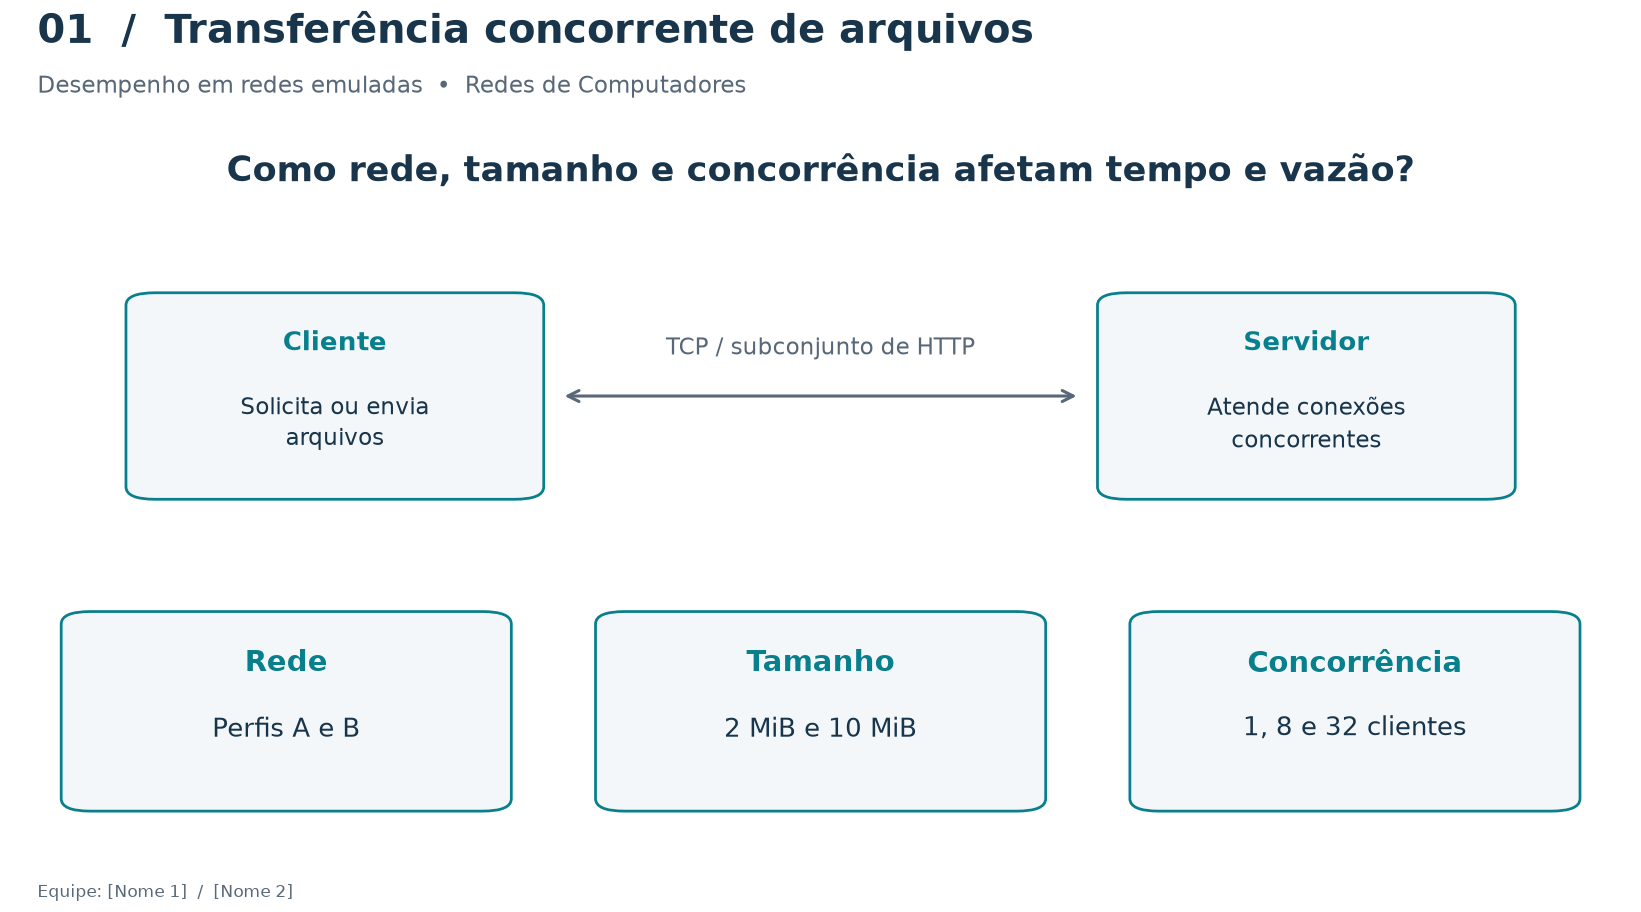

In [14]:
fig,ax=tela(1,'Transferência concorrente de arquivos','Desempenho em redes emuladas  •  Redes de Computadores',
            'Equipe: '+'  /  '.join(NOMES))
ax.text(.5,.94,'Como rede, tamanho e concorrência afetam tempo e vazão?',ha='center',fontsize=23,color=AZUL,weight='bold')
caixa(ax,.08,.49,.24,.28,'Cliente','Solicita ou envia arquivos',wrap=23)
caixa(ax,.68,.49,.24,.28,'Servidor','Atende conexões concorrentes',wrap=26)
seta(ax,(.34,.63),(.66,.63),dupla=True)
ax.text(.5,.69,'TCP / subconjunto de HTTP',ha='center',color=CINZA,fontsize=15)
for x,title,body in [(.04,'Rede','Perfis A e B'),(.37,'Tamanho','2 MiB e 10 MiB'),(.70,'Concorrência','1, 8 e 32 clientes')]:
    caixa(ax,x,.04,.26,.27,title,body,fonte=19,wrap=25)
salvar_visual(fig,1,'objetivo','Pergunta central e fatores investigados')
instrucoes_slide(1,'Usar objetivo.png como base visual. Substituir os nomes na configuração e regenerar. Apresentar problema e motivação.')

## Slide 2 — Aplicação e arquitetura · 0:35–1:25

Gera o fluxo TCP, as operações e os mecanismos de concorrência e publicação. É uma ilustração da implementação, sem capturas simuladas.

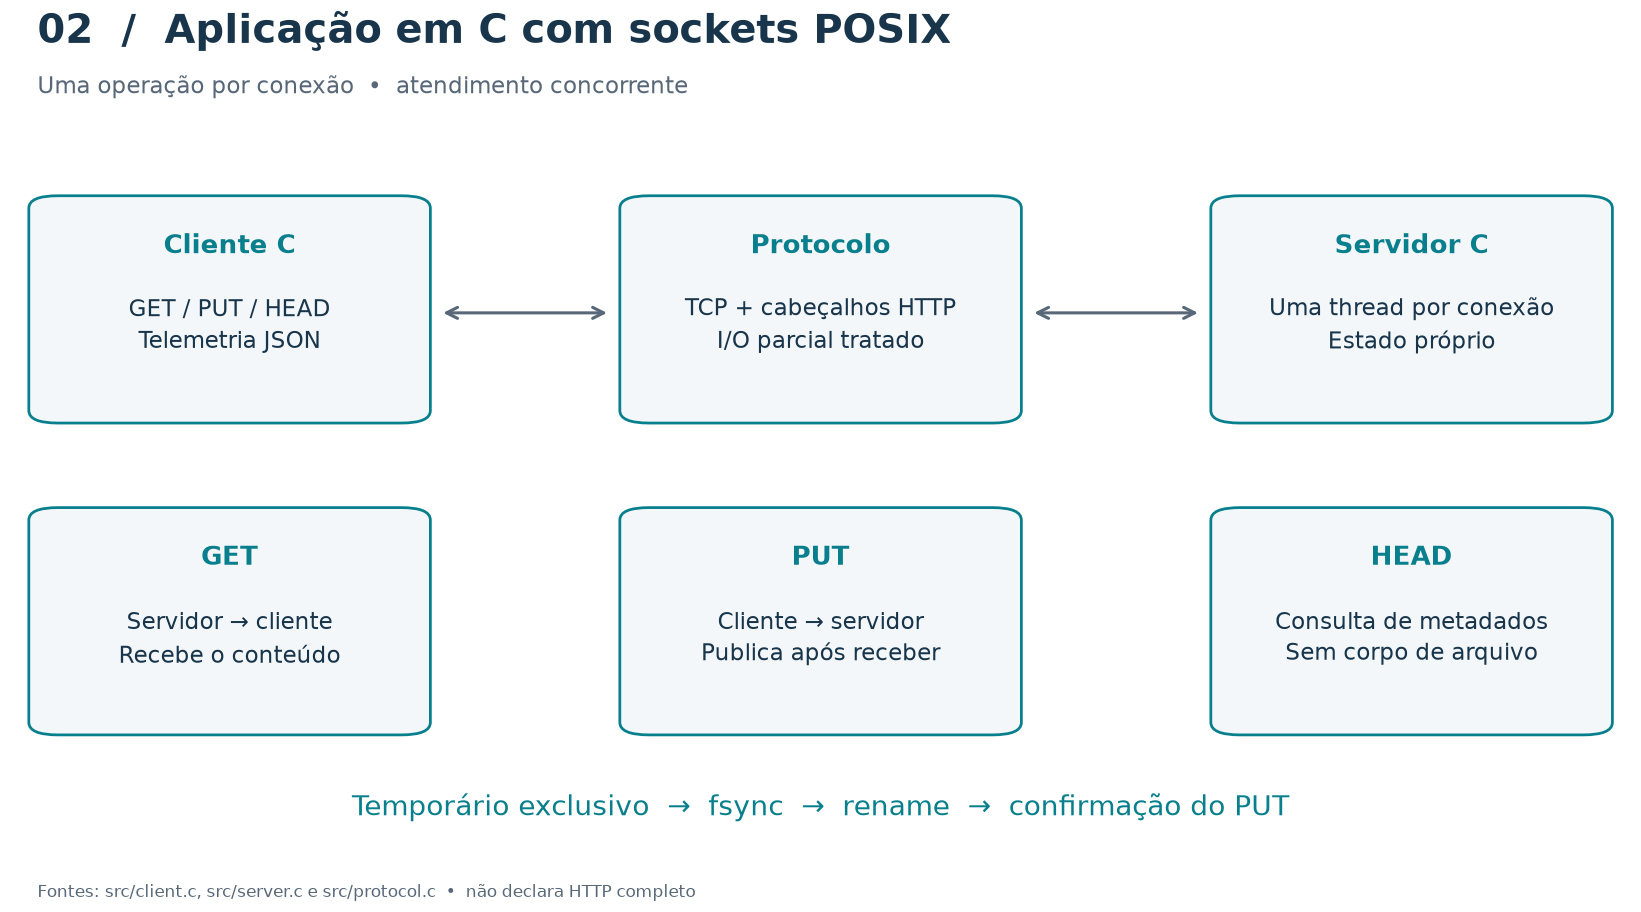

In [15]:
fig,ax=tela(2,'Aplicação em C com sockets POSIX','Uma operação por conexão  •  atendimento concorrente',
            'Fontes: src/client.c, src/server.c e src/protocol.c  •  não declara HTTP completo')
for x,title,body in [(.02,'Cliente C','GET / PUT / HEAD\nTelemetria JSON'),(.385,'Protocolo','TCP + cabeçalhos HTTP\nI/O parcial tratado'),
                     (.75,'Servidor C','Uma thread por conexão\nEstado próprio')]:
    caixa(ax,x,.60,.23,.31,title,body,wrap=26)
seta(ax,(.265,.75),(.37,.75),dupla=True); seta(ax,(.63,.75),(.735,.75),dupla=True)
for x,title,body in [(.02,'GET','Servidor → cliente\nRecebe o conteúdo'),(.385,'PUT','Cliente → servidor\nPublica após receber'),
                     (.75,'HEAD','Consulta de metadados\nSem corpo de arquivo')]:
    caixa(ax,x,.15,.23,.31,title,body,wrap=25)
ax.text(.5,.025,'Temporário exclusivo  →  fsync  →  rename  →  confirmação do PUT',ha='center',fontsize=18,color=VERDE)
salvar_visual(fig,2,'arquitetura','Arquitetura, operações e publicação')
texto_slide(2,'arquitetura.mmd','flowchart LR\n    C[Cliente C] <-->|TCP / subconjunto HTTP| S[Servidor C]\n'
            '    S --> T[Thread por conexão]\n    T --> U[Temporário exclusivo]\n    U --> F[fsync]\n    F --> R[rename]\n'
            '    R --> A[Confirmação PUT]','Fonte Mermaid editável do diagrama')
instrucoes_slide(2,'Inserir arquitetura.png ou arquitetura.svg. arquitetura.mmd permite editar o esquema em Mermaid; as imagens já estão renderizadas.')

## Slide 3 — Topologia e perfis · 1:25–2:10

Desenha os nós e enlaces do XML, destaca o gargalo e exporta os parâmetros A/B. Divergências XML × matriz interrompem este bloco. O esquema não comprova rotas ou calibração.

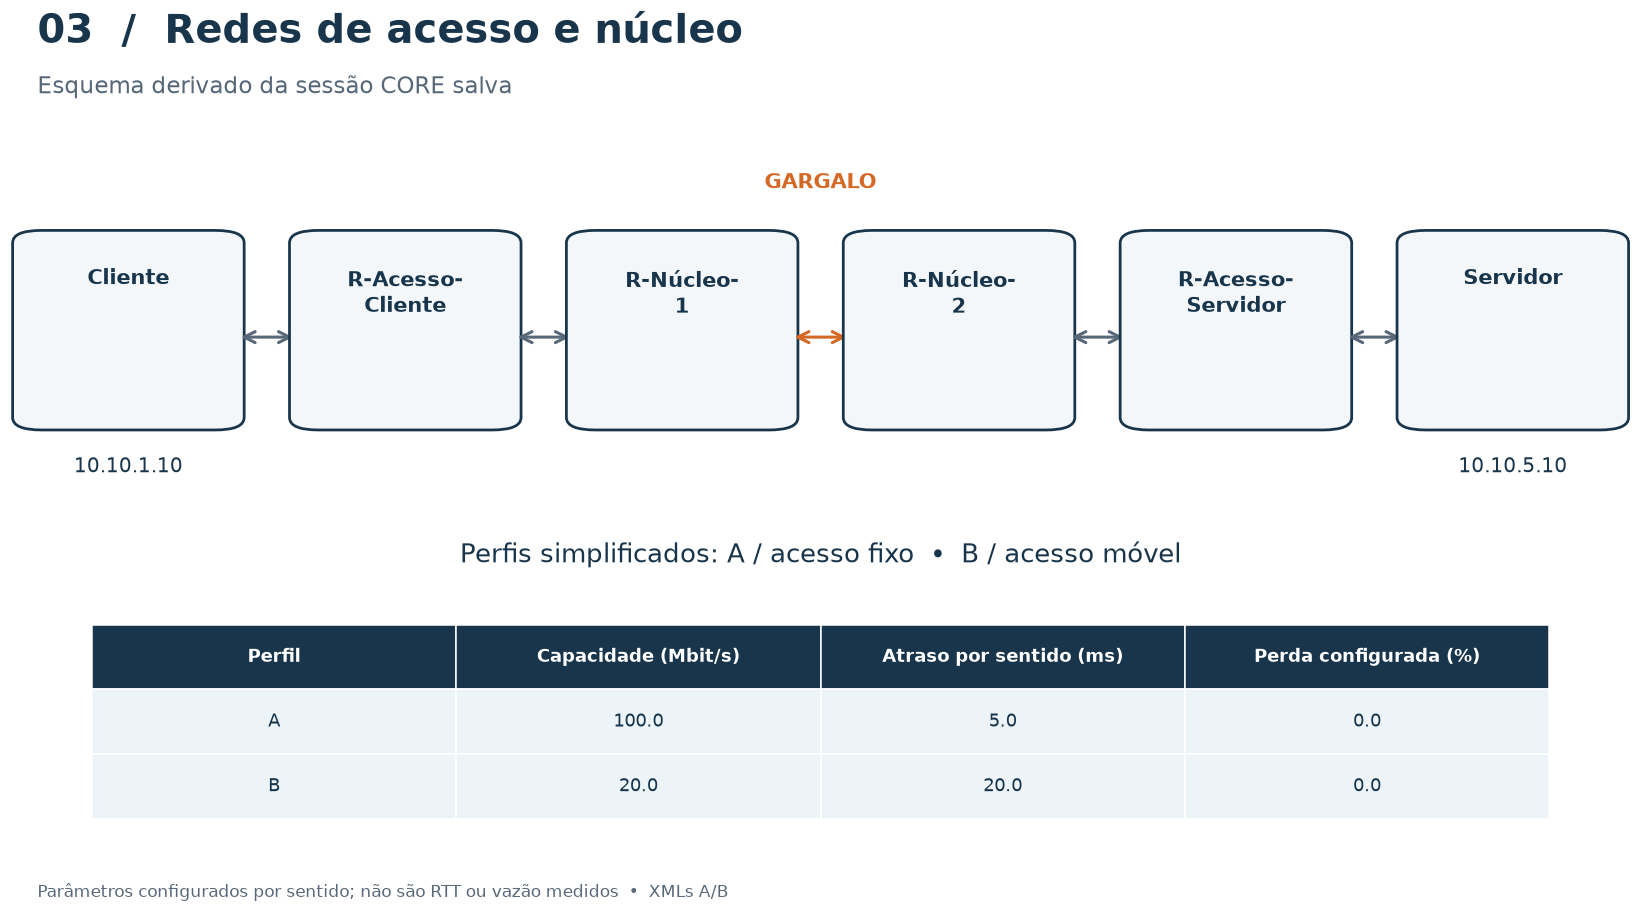

In [16]:
def ler_topologia(profile):
    path=ROOT/f'topology/trabalho1-etapa4-perfil-{profile}.xml'
    xml=ET.parse(path).getroot()
    devices={d.attrib['id']:d.attrib['name'] for d in xml.findall('./devices/device')}
    links=[]
    for link in xml.findall('./links/link'):
        opt=link.find('options').attrib
        a,b=link.attrib['node1'],link.attrib['node2']
        i1,i2=link.find('iface1').attrib,link.find('iface2').attrib
        links.append({'node1':a,'node2':b,'name1':devices[a],'name2':devices[b],
                      'ip1':i1['ip4'],'ip2':i2['ip4'],
                      'network':str(ipaddress.ip_network(f"{i1['ip4']}/{i1['ip4_mask']}",strict=False)),
                      'bandwidth_mbps':float(opt['bandwidth'])/1e6,'delay_oneway_ms':float(opt['delay'])/1000,
                      'loss_pct':float(opt['loss'])})
    return path,devices,links

xml_sources,profile_rows=[],[]
for profile in sorted(PLAN.profile.unique()):
    xml_path,devices,links=ler_topologia(profile)
    bottlenecks=[link for link in links if link['bandwidth_mbps']>0 and link['delay_oneway_ms']>0]
    assert len(bottlenecks)==1,'Revise o enlace de gargalo no XML.'
    b=bottlenecks[0]
    planned=PLAN.loc[PLAN.profile.eq(profile),['bandwidth_mbps','delay_oneway_ms']].drop_duplicates()
    assert len(planned)==1
    assert np.isclose(b['bandwidth_mbps'],planned.iloc[0].bandwidth_mbps) and np.isclose(
        b['delay_oneway_ms'],planned.iloc[0].delay_oneway_ms),'XML diverge da matriz: revise antes de usar no vídeo.'
    profile_rows.append({'Perfil':profile,'Capacidade (Mbit/s)':b['bandwidth_mbps'],
                         'Atraso por sentido (ms)':b['delay_oneway_ms'],'Perda configurada (%)':b['loss_pct']})
    xml_sources.append({'path':str(xml_path.relative_to(ROOT)),'sha256':hashlib.sha256(xml_path.read_bytes()).hexdigest()})
    csv_slide(3,f'enlaces_perfil_{profile}.csv',pd.DataFrame(links),f'Enlaces e parâmetros do XML {profile}')
profile_table=pd.DataFrame(profile_rows)
csv_slide(3,'perfis.csv',profile_table,'Parâmetros dos XMLs conferidos com a matriz')
_,devices,links=ler_topologia('A')
start=next(k for k,v in devices.items() if v.lower()=='cliente')
end=next(k for k,v in devices.items() if v.lower()=='servidor')
queue=[(start,[start])]; order=None
while queue:
    current,route=queue.pop(0)
    if current==end:
        order=route; break
    for link in links:
        other=link['node2'] if link['node1']==current else link['node1'] if link['node2']==current else None
        if other is not None and other not in route:
            queue.append((other,route+[other]))
assert order is not None,'Cliente e servidor não estão conectados no XML.'
fig,ax=tela(3,'Redes de acesso e núcleo','Esquema derivado da sessão CORE salva',
            'Parâmetros configurados por sentido; não são RTT ou vazão medidos  •  XMLs A/B')
xs=np.linspace(.01,.865,len(order))
for i,node in enumerate(order):
    name=devices[node].replace('R-Acesso-','R-Acesso-\n').replace('R-Nucleo-','R-Núcleo-\n')
    caixa(ax,xs[i],.59,.125,.27,name,cor=AZUL,fonte=14)
    if node in [start,end]:
        iface_ip=next(link['ip1'] if link['node1']==node else link['ip2'] for link in links if node in [link['node1'],link['node2']])
        ax.text(xs[i]+.0625,.52,iface_ip,ha='center',color=AZUL,fontsize=13)
    if i<len(order)-1:
        link=next(l for l in links if {l['node1'],l['node2']}=={node,order[i+1]})
        bottleneck=link['bandwidth_mbps']>0 and link['delay_oneway_ms']>0
        seta(ax,(xs[i]+.13,.715),(xs[i+1]-.005,.715),cor=LARANJA if bottleneck else CINZA,dupla=True)
        if bottleneck:
            ax.text((xs[i]+.125+xs[i+1])/2,.93,'GARGALO',ha='center',fontsize=14,color=LARANJA,weight='bold')
ax.text(.5,.39,'Perfis simplificados: A / acesso fixo  •  B / acesso móvel',ha='center',fontsize=17,color=AZUL)
tab=ax.table(cellText=profile_table.astype(str).values,colLabels=profile_table.columns,cellLoc='center',bbox=[.05,.02,.90,.28])
tab.auto_set_font_size(False); tab.set_fontsize(12)
for (row,col),cell in tab.get_celld().items():
    cell.set_edgecolor('white'); cell.set_facecolor(AZUL if row==0 else '#edf4f7')
    cell.set_text_props(color='white' if row==0 else AZUL,weight='bold' if row==0 else 'normal')
salvar_visual(fig,3,'topologia','Nós e gargalo derivados do XML, com parâmetros dos perfis')
instrucoes_slide(3,'Usar topologia.png como desenho da sessão salva. Para uma captura real, abrir no CORE o XML '
                    'do perfil desejado, enquadrar nós/gargalo e gravar a tela separadamente. O notebook não inicia '
                    'sessão. O campo zero de capacidade em outros enlaces é apenas o parâmetro salvo, não uma '
                    'vazão medida zero. Rotas e calibração exigem validação própria.')

## Slide 4 — Matriz e análise · 2:10–3:00

Gera os fatores, totais planejados e o fluxo requisições → médias por rodada → IC95%. Exporta a matriz completa sem alterar seu status de planejamento.

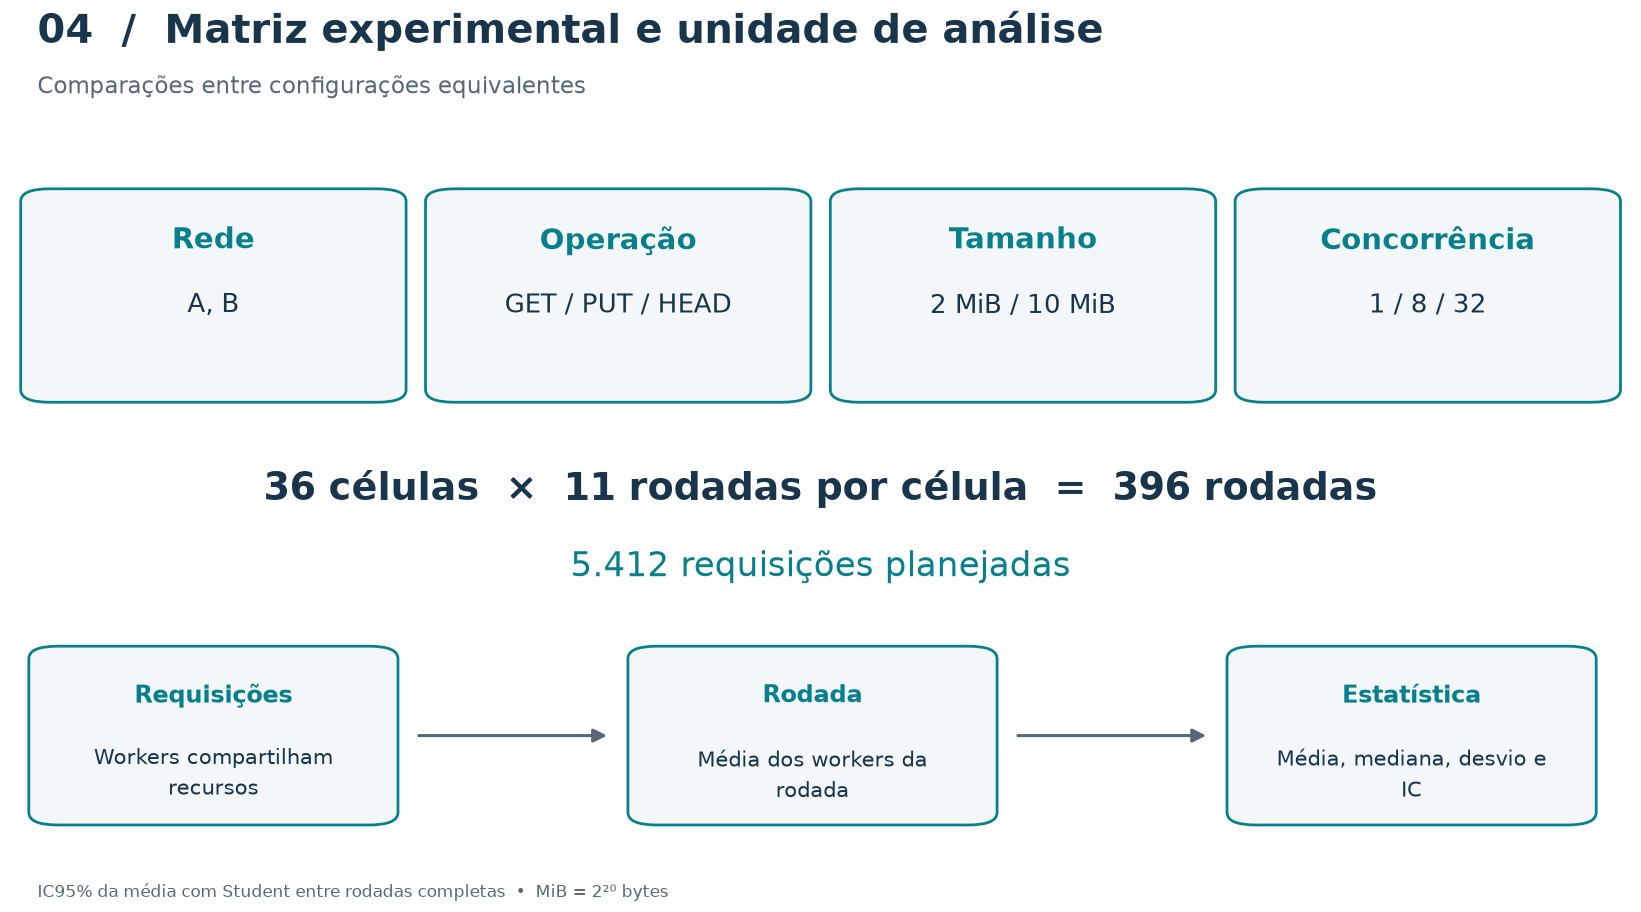

In [17]:
planned_rounds=int(PLAN.repetitions.sum())
planned_requests=int((PLAN.concurrency*PLAN.repetitions).sum())
csv_slide(4,'matriz.csv',PLAN.copy(),'Matriz experimental versionada')
fig,ax=tela(4,'Matriz experimental e unidade de análise','Comparações entre configurações equivalentes',
            'IC95% da média com Student entre rodadas completas  •  MiB = 2²⁰ bytes')
factors_view=[('Rede',', '.join(sorted(PLAN.profile.unique()))),('Operação',' / '.join(PLAN.operation.drop_duplicates())),
              ('Tamanho',' / '.join(f'{x/2**20:g} MiB' for x in sorted(PLAN.file_size_bytes.unique()))),
              ('Concorrência',' / '.join(str(x) for x in sorted(PLAN.concurrency.unique())))]
for i,(title,body) in enumerate(factors_view):
    caixa(ax,.015+i*.25,.63,.22,.29,title,body,fonte=19,wrap=22)
reps_label=str(PLAN.repetitions.iloc[0]) if PLAN.repetitions.nunique()==1 else 'n variável'
ax.text(.5,.48,f'{len(PLAN)} células  ×  {reps_label} rodadas por célula  =  {planned_rounds} rodadas',
        ha='center',fontsize=25,color=AZUL,weight='bold')
ax.text(.5,.37,f'{numero_pt(planned_requests,0)} requisições planejadas',ha='center',fontsize=22,color=VERDE)
for x,title,body in [(.02,'Requisições','Workers compartilham recursos'),(.39,'Rodada','Média dos workers da rodada'),
                     (.76,'Estatística','Média, mediana, desvio e IC')]:
    caixa(ax,x,.02,.21,.24,title,body,fonte=16,wrap=24)
seta(ax,(.25,.14),(.37,.14)); seta(ax,(.62,.14),(.74,.14))
salvar_visual(fig,4,'matriz_metodo','Fatores, quantidades planejadas e unidade do IC')
instrucoes_slide(4,'Usar matriz_metodo.png. matriz.csv contém todas as células. Os totais são planejados; '
                    'a cobertura observada está no slide 5. A independência entre rodadas é uma hipótese, não uma garantia do gráfico.')

## Slide 5 — Demonstração e cobertura · 3:00–3:45

Gera o painel de cobertura, exporta exemplos reais GET/PUT e escreve instruções para o clipe de aproximadamente 15 segundos. **Não executa servidor, cliente, CORE nem gera vídeo fictício.**

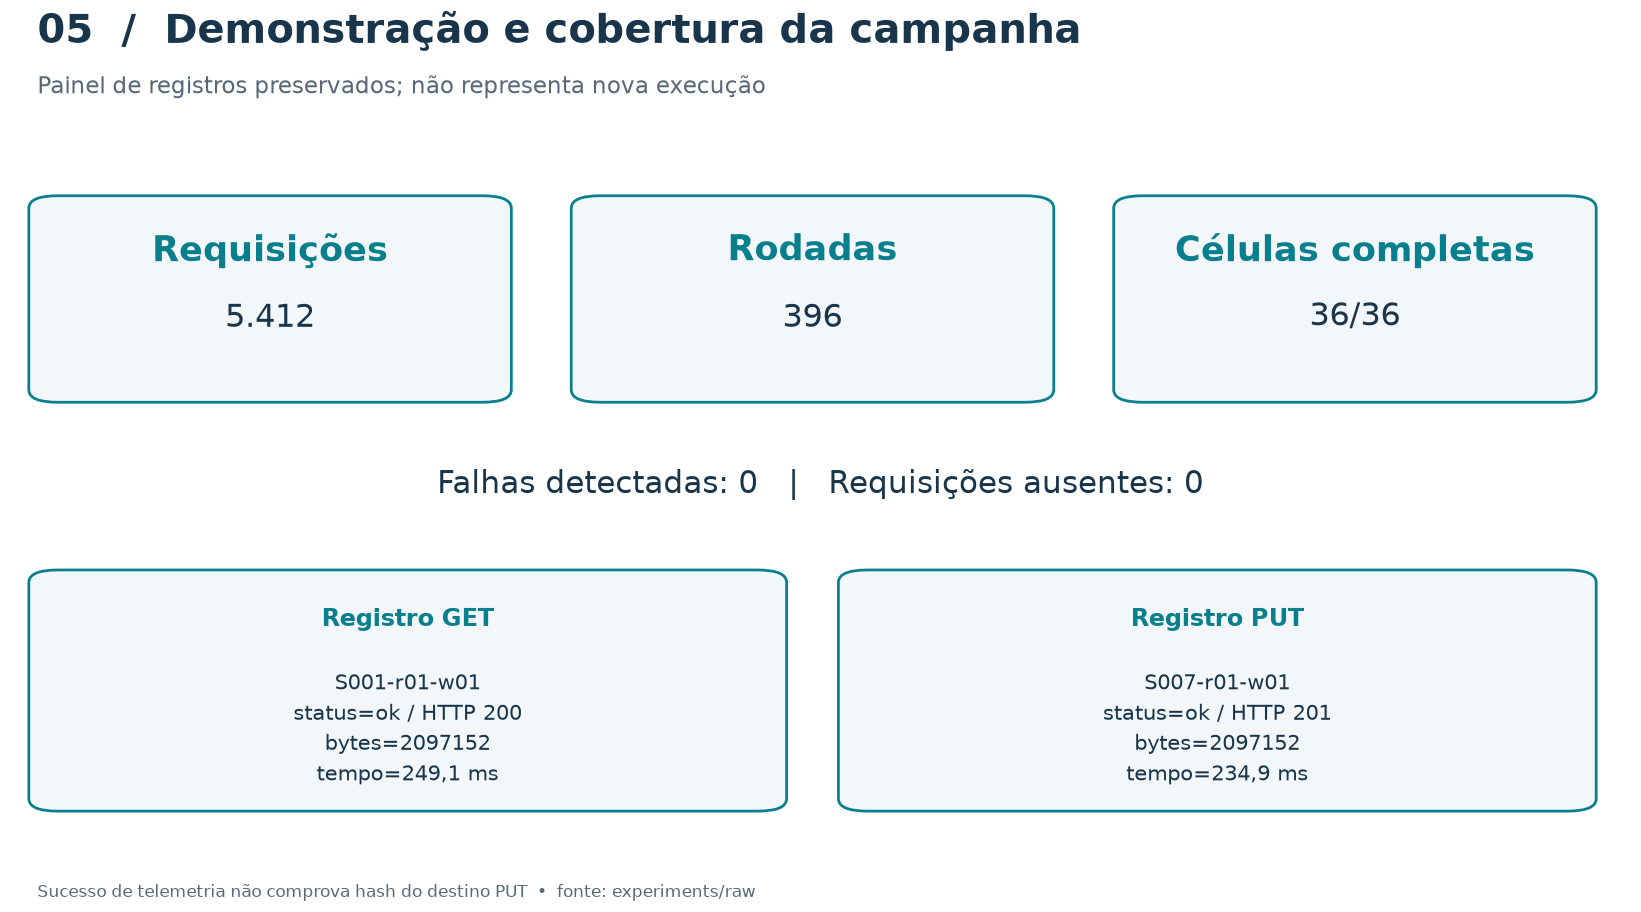

In [18]:
csv_slide(5,'cobertura.csv',coverage,'Cobertura, ausências e falhas por célula')
examples=[]
for operation in ['GET','PUT']:
    part=req.loc[req.operation.eq(operation)&req.valid].sort_values(['scenario_id','repetition','worker'])
    assert len(part),f'Sem exemplo válido para {operation}'
    record_path=ROOT/part.iloc[0].source
    d=json.loads(record_path.read_text())
    examples.append({'source':str(record_path.relative_to(ROOT)),'identifier':d['identifier'],'client_result':d['client_result']})
texto_slide(5,'registros_reais.json',json.dumps(examples,ensure_ascii=False,indent=2),'Exemplos GET/PUT copiados dos registros originais')
fig,ax=tela(5,'Demonstração e cobertura da campanha','Painel de registros preservados; não representa nova execução',
            'Sucesso de telemetria não comprova hash do destino PUT  •  fonte: experiments/raw')
for x,title,body in [(.02,'Requisições',numero_pt(len(req),0)),(.355,'Rodadas',numero_pt(len(rounds),0)),
                     (.69,'Células completas',f'{int(coverage.enough_rounds.sum())}/{len(PLAN)}')]:
    caixa(ax,x,.63,.28,.28,title,body,fonte=23,wrap=22)
ax.text(.5,.49,f'Falhas detectadas: {len(failures)}   |   Requisições ausentes: {int(coverage.missing_requests.sum())}',
        ha='center',color=AZUL,fontsize=20)
for x,ex in zip([.02,.52],examples):
    c=ex['client_result']
    body=f"{ex['identifier']}\nstatus={c['status']} / HTTP {c['status_code']}\nbytes={c['bytes']}\ntempo={numero_pt(c['elapsed_ms'])} ms"
    caixa(ax,x,.04,.45,.33,f"Registro {c['method']}",body,fonte=16,wrap=45)
salvar_visual(fig,5,'cobertura_registros','Cobertura e exemplos reais sem simular terminal ao vivo')
instrucoes_slide(5,'Usar cobertura_registros.png e um clipe real de cerca de 15 segundos. registros_reais.json '
                    'pode ser exibido como alternativa rotulada “registro da campanha”. Para gravar: '
                    '1) preparar cliente/servidor C; 2) mostrar GET e PUT completos e sua saída; '
                    '3) identificar CORE ou localhost; 4) guardar o clipe nesta pasta com nome próprio, '
                    'como demonstracao_real.mp4; 5) inserir o clipe na apresentação. O notebook não executa '
                    'essas operações nem sobrescreve o vídeo. Sobrescrita só deve ser anunciada com evidência '
                    'antes/depois. Localhost demonstra função, não valida a topologia CORE.')

## Slide 6 — Tempo de resposta · 3:45–4:45

Gera GET A/B com linhas de 2/10 MiB e IC95%, mais tabela GET de 10 MiB com C=1/32. Gráficos usam **segundos** e a tabela segue o roteiro em **milissegundos**. PUT é material de apoio separado.

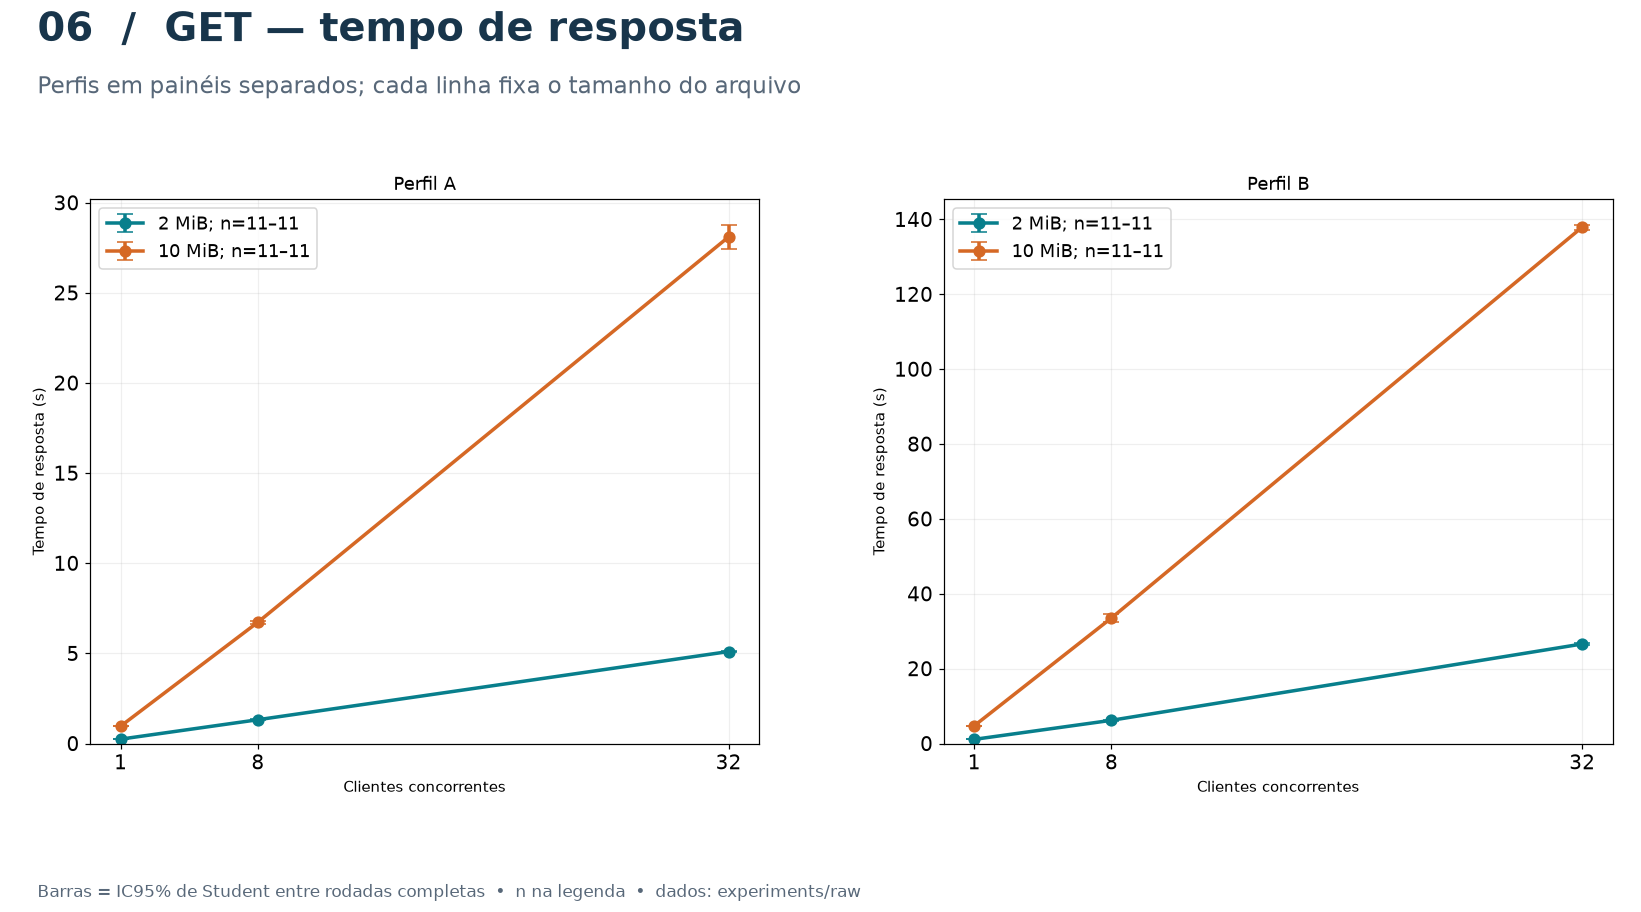

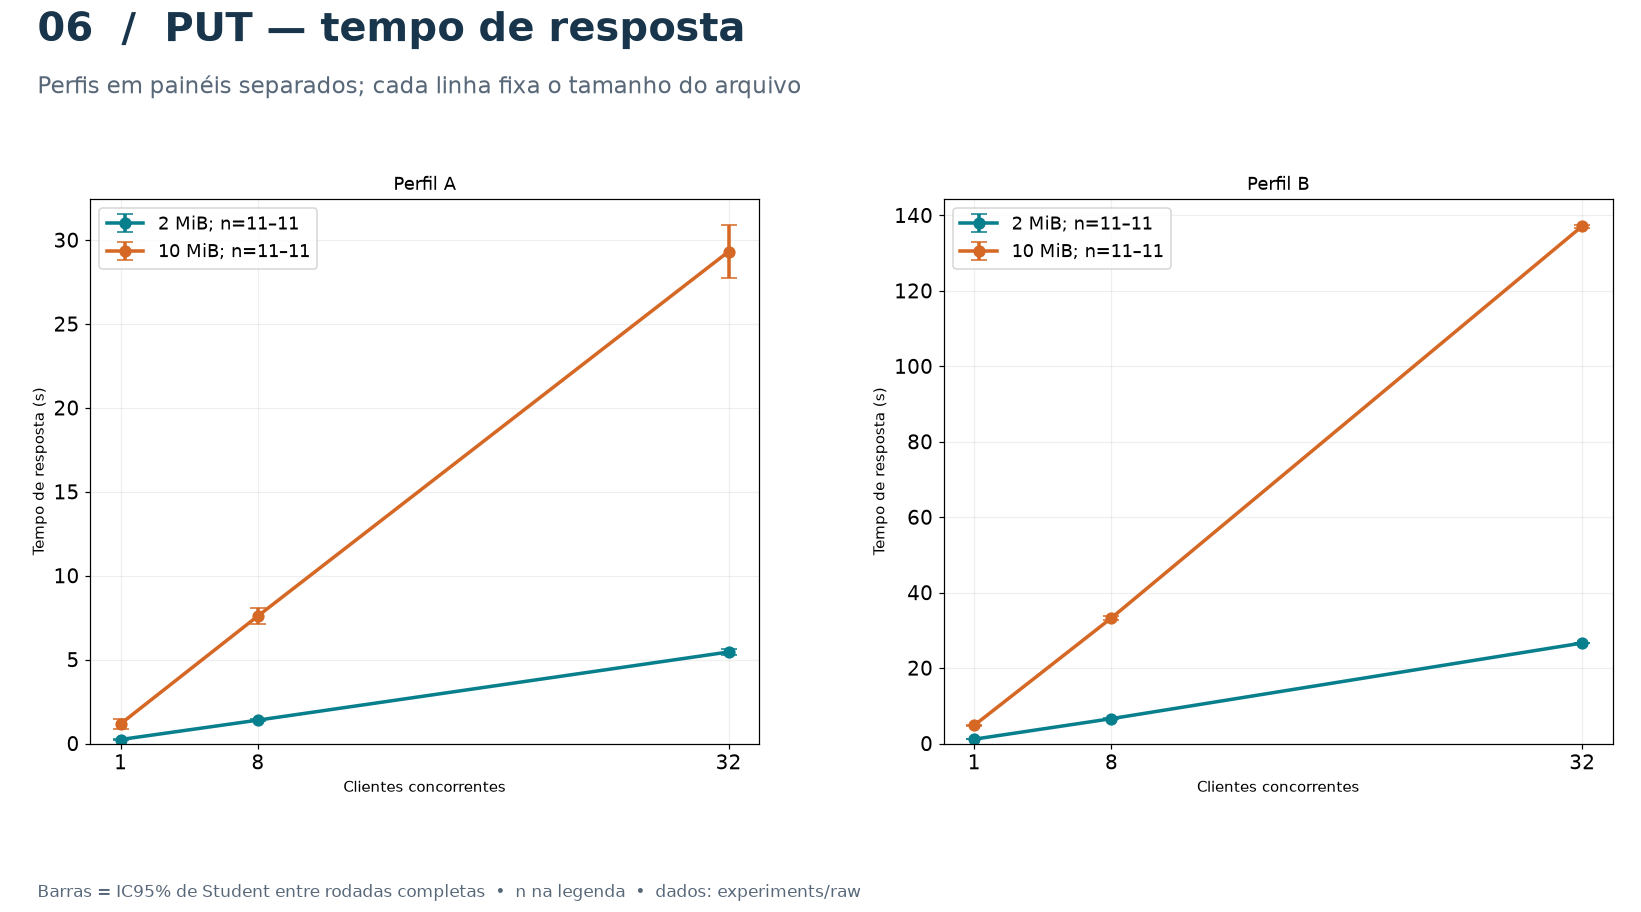

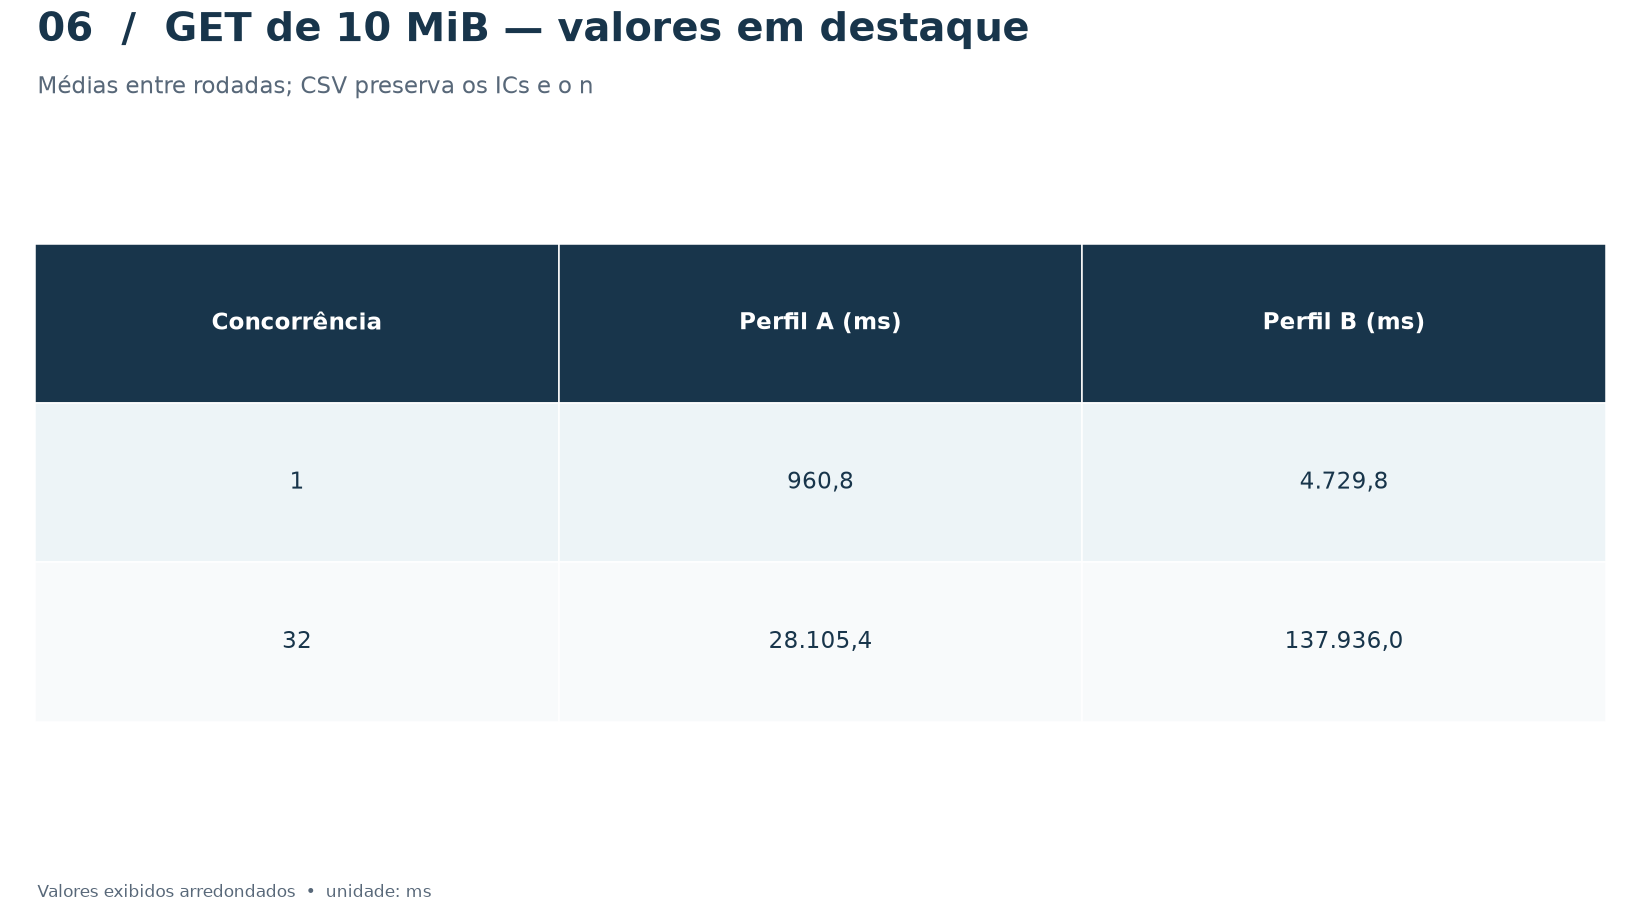

In [19]:
def grafico_slides(slide,operation,metric,divisor,ylabel,nome):
    fig,_=tela(slide,f'{operation} — '+('tempo de resposta' if metric=='response_ms' else 'vazão útil individual'),
               'Perfis em painéis separados; cada linha fixa o tamanho do arquivo',
               'Barras = IC95% de Student entre rodadas completas  •  n na legenda  •  dados: experiments/raw')
    for j,profile in enumerate(['A','B']):
        ax=fig.add_axes([.085+j*.485,.20,.38,.55])
        subset=summary.loc[summary.metric.eq(metric)&summary.operation.eq(operation)&summary.profile.eq(profile)]
        for size,group in subset.groupby('size_mib'):
            group=group.sort_values('concurrency')
            ax.errorbar(group.concurrency,group['mean']/divisor,yerr=group.half/divisor,
                        marker='o',markersize=7,capsize=5,linewidth=2.3,color=VERDE if size==2 else LARANJA,
                        label=f'{size:g} MiB; n={int(group.n.min())}–{int(group.n.max())}')
        ax.set(title=f'Perfil {profile}',xlabel='Clientes concorrentes',ylabel=ylabel,xticks=[1,8,32])
        ax.tick_params(labelsize=13); ax.set_ylim(bottom=0); ax.legend(fontsize=12); ax.grid(True,alpha=.2)
    salvar_visual(fig,slide,nome,f'{operation}: {metric} por concorrência com IC95%')

def destaques_get(slide,metric,unidade,casas,nome):
    raw_table=summary.loc[summary.metric.eq(metric)&summary.operation.eq('GET')&summary.file_size_bytes.eq(10*2**20)
                          &summary.concurrency.isin([1,32]),['profile','concurrency','n','mean','ci95_low','ci95_high']].copy()
    csv_slide(slide,nome+'.csv',raw_table,'Valores exatos GET 10 MiB, C=1/32, com IC95%')
    pivot=raw_table.pivot(index='concurrency',columns='profile',values='mean').reset_index()
    formatted=pd.DataFrame({'Concorrência':pivot.concurrency.astype(int),
                             f'Perfil A ({unidade})':pivot.A.map(lambda v:numero_pt(v,casas)),
                             f'Perfil B ({unidade})':pivot.B.map(lambda v:numero_pt(v,casas))})
    tabela_visual(slide,nome,formatted,'GET de 10 MiB — valores em destaque',
                   'Médias entre rodadas; CSV preserva os ICs e o n',
                   f'Valores exibidos arredondados  •  unidade: {unidade}')

for op in ['GET','PUT']:
    grafico_slides(6,op,'response_ms',1000,'Tempo de resposta (s)',f'{op.lower()}_tempo')
csv_slide(6,'estatisticas_tempo.csv',summary.loc[summary.metric.eq('response_ms')],'Estatísticas de tempo de todas as células')
destaques_get(6,'response_ms','ms',1,'get_destaques_tempo')
instrucoes_slide(6,'Inserir get_tempo.png e get_destaques_tempo.png ou sua tabela CSV. Gráfico em segundos; '
                    'tabela em milissegundos. put_tempo.png é apoio, separado de GET. A diferença A/B não isola '
                    'o efeito do atraso: a capacidade também muda. Os painéis usam escalas verticais próprias, identificadas nos eixos.')

## Slide 7 — Vazão individual · 4:45–5:40

Gera GET A/B e tabela em Mbit/s, com PUT como apoio. A soma das taxas individuais não é apresentada como goodput agregado.

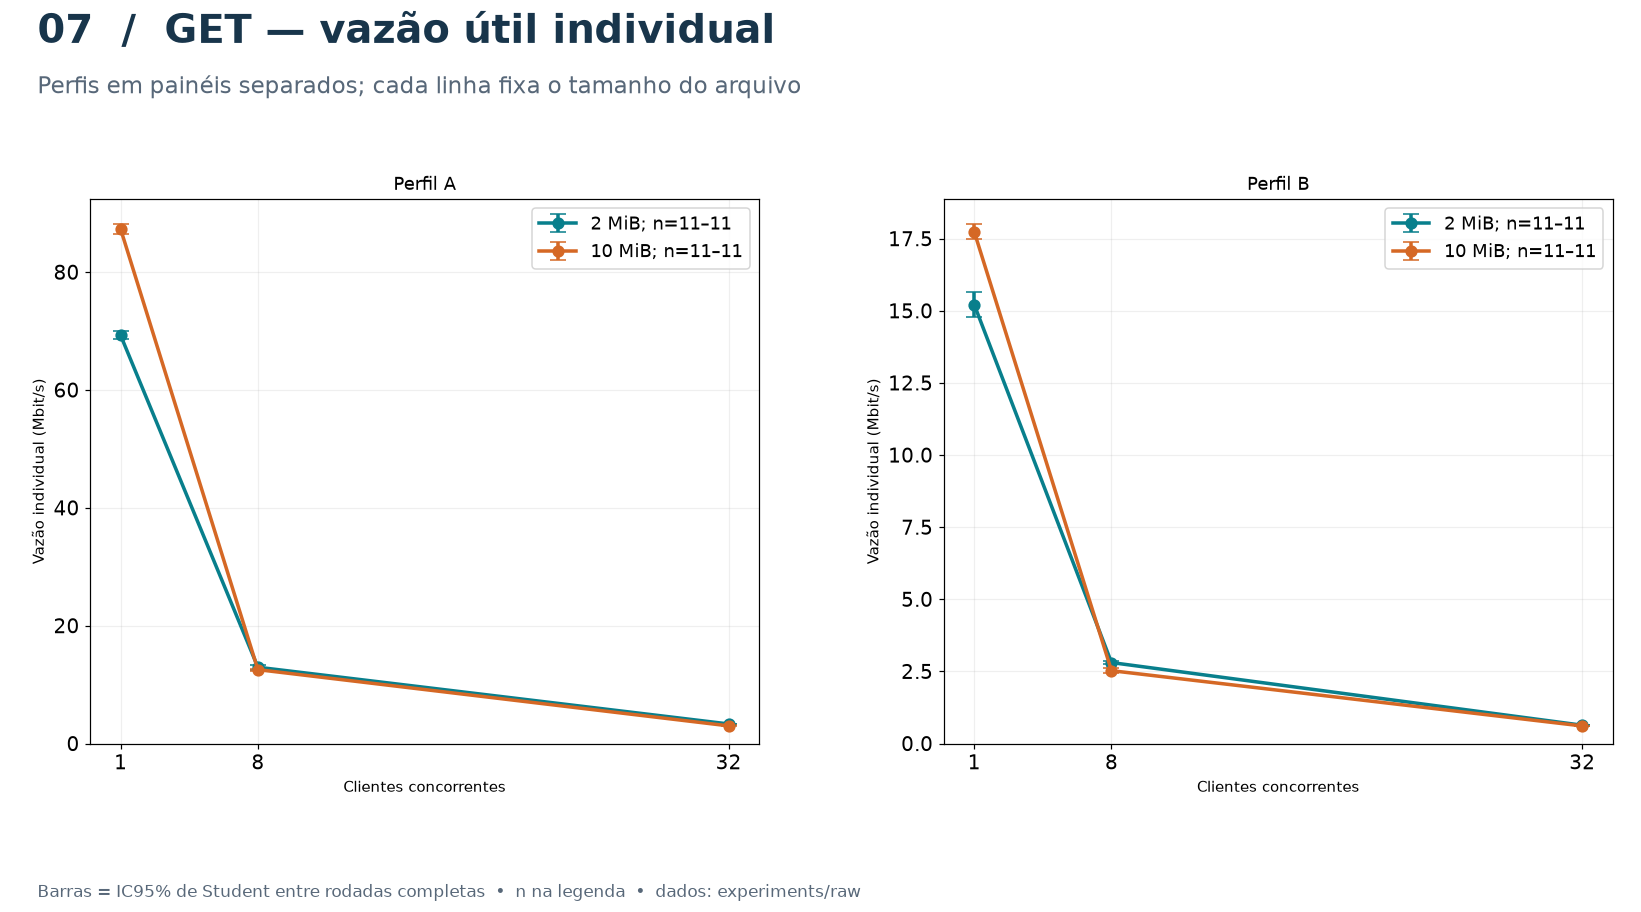

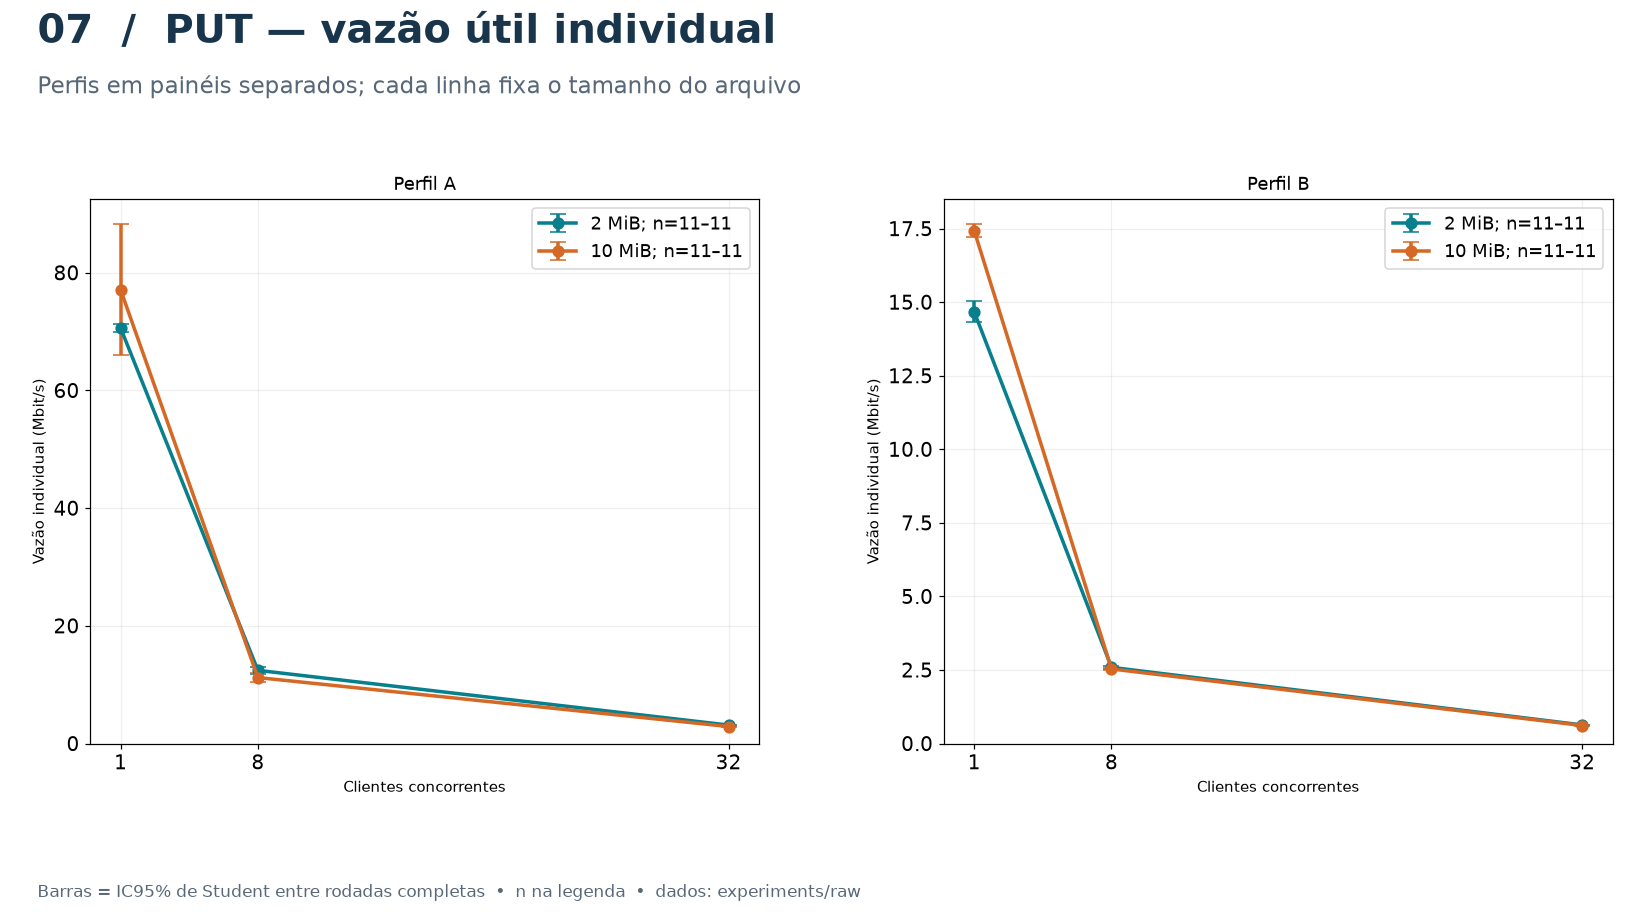

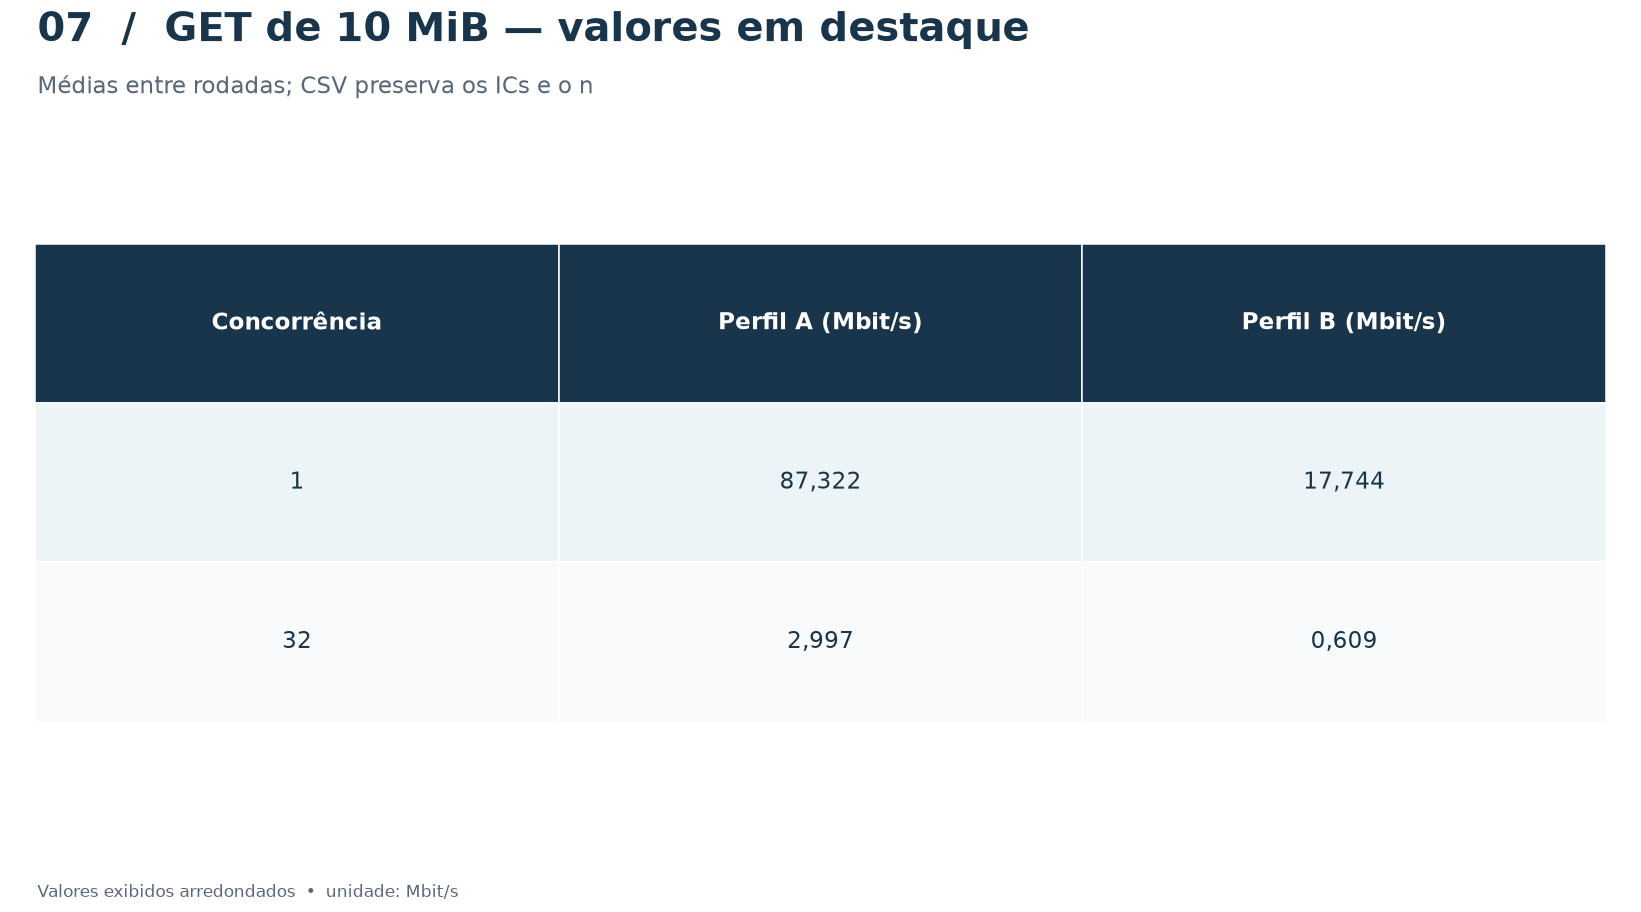

In [20]:
for op in ['GET','PUT']:
    grafico_slides(7,op,'individual_mbps',1,'Vazão individual (Mbit/s)',f'{op.lower()}_vazao_individual')
csv_slide(7,'estatisticas_vazao_individual.csv',summary.loc[summary.metric.eq('individual_mbps')&summary.operation.ne('HEAD')],
           'Estatísticas de vazão individual GET/PUT, sem HEAD')
destaques_get(7,'individual_mbps','Mbit/s',3,'get_destaques_vazao')
texto_slide(7,'FORMULA.md','# Vazão individual\n\n`bytes úteis × 8 / (elapsed_ms / 1000) / 10^6`\n\n'
            'A média é calculada entre workers da rodada, e depois entre rodadas. Não confundir média de taxas '
            'com taxa calculada a partir do tempo médio. Não somar taxas para afirmar vazão agregada.',
            'Fórmula e interpretação da métrica')
instrucoes_slide(7,'Usar get_vazao_individual.png e get_destaques_vazao.png, ou os CSVs. Adicionar a fórmula de '
                    'FORMULA.md. PUT é apoio. Os painéis não medem vazão agregada nem provam queda da capacidade '
                    'total do serviço; observar as escalas verticais próprias de cada perfil.')

## Slide 8 — Operações e HEAD · 5:40–6:20

Gera tabela GET/PUT de 10 MiB e HEAD de referência 2 MiB, com C=1, e diagrama dos sentidos do tráfego. HEAD não recebe vazão de conteúdo.

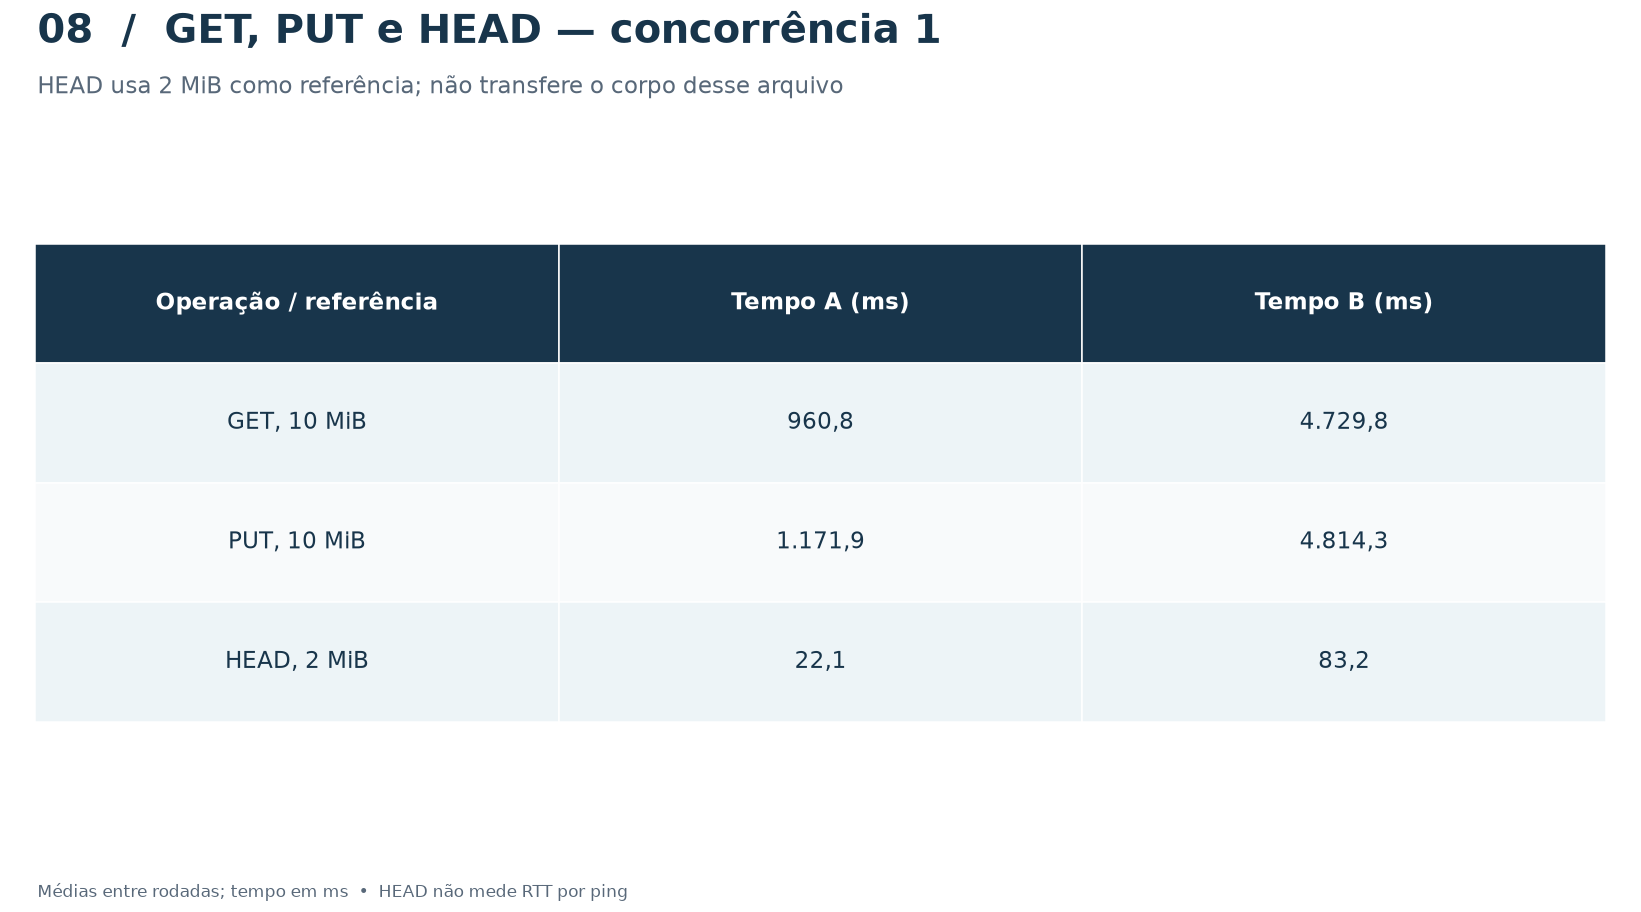

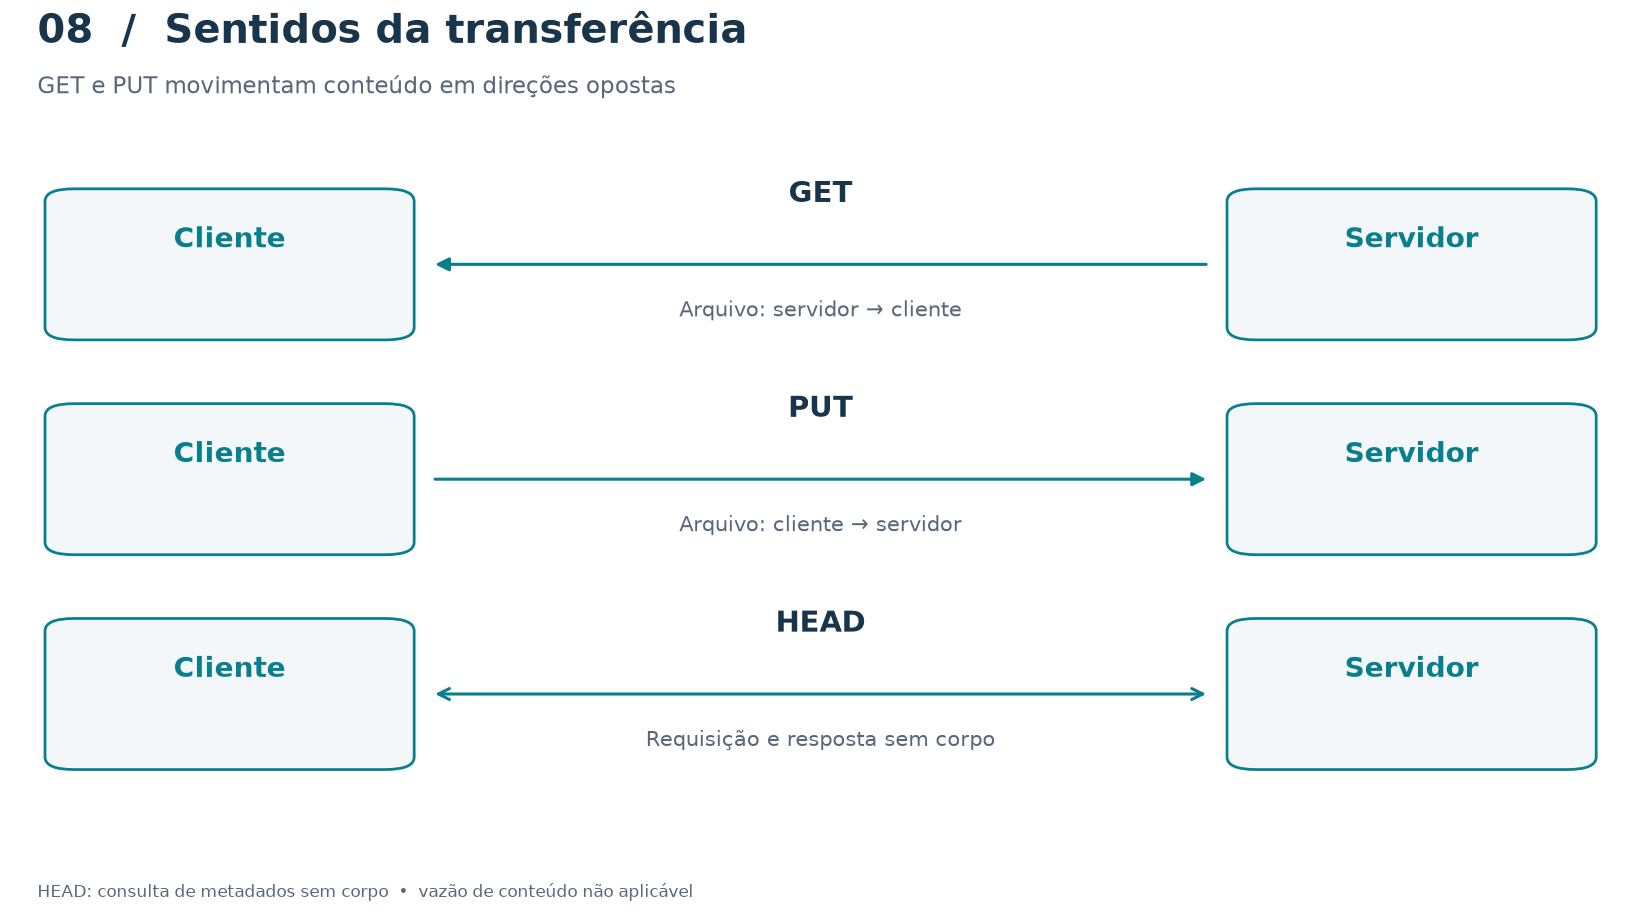

In [21]:
criteria=(summary.metric.eq('response_ms')&summary.concurrency.eq(1)&
          ((summary.operation.isin(['GET','PUT'])&summary.file_size_bytes.eq(10*2**20))|
           (summary.operation.eq('HEAD')&summary.file_size_bytes.eq(2*2**20))))
ops_stats=summary.loc[criteria,['operation','file_size_bytes','profile','n','mean','ci95_low','ci95_high']].copy()
csv_slide(8,'operacoes_tempo.csv',ops_stats,'Tempo por operação, C=1, com IC95%')
ops_pivot=ops_stats.pivot(index=['operation','file_size_bytes'],columns='profile',values='mean').reset_index()
ops_pivot['operation']=pd.Categorical(ops_pivot.operation,['GET','PUT','HEAD'],ordered=True)
ops_pivot=ops_pivot.sort_values('operation')
ops_view=pd.DataFrame({'Operação / referência':[f'{op}, {size/2**20:g} MiB' for op,size in zip(ops_pivot.operation,ops_pivot.file_size_bytes)],
                       'Tempo A (ms)':ops_pivot.A.map(numero_pt).to_numpy(),'Tempo B (ms)':ops_pivot.B.map(numero_pt).to_numpy()})
tabela_visual(8,'comparacao_operacoes',ops_view,'GET, PUT e HEAD — concorrência 1',
               'HEAD usa 2 MiB como referência; não transfere o corpo desse arquivo',
               'Médias entre rodadas; tempo em ms  •  HEAD não mede RTT por ping')
fig,ax=tela(8,'Sentidos da transferência','GET e PUT movimentam conteúdo em direções opostas',
            'HEAD: consulta de metadados sem corpo  •  vazão de conteúdo não aplicável')
for y,method,desc in [(.72,'GET','Arquivo: servidor → cliente'),(.41,'PUT','Arquivo: cliente → servidor'),
                      (.10,'HEAD','Requisição e resposta sem corpo')]:
    caixa(ax,.03,y,.21,.20,'Cliente',fonte=18); caixa(ax,.76,y,.21,.20,'Servidor',fonte=18)
    a,b=((.74,y+.10),(.26,y+.10)) if method=='GET' else ((.26,y+.10),(.74,y+.10))
    seta(ax,a,b,cor=VERDE,dupla=method=='HEAD')
    ax.text(.5,y+.19,method,ha='center',fontsize=19,color=AZUL,weight='bold')
    ax.text(.5,y+.025,desc,ha='center',fontsize=14,color=CINZA)
salvar_visual(fig,8,'sentidos_operacoes','Sentidos do conteúdo e consulta HEAD')
instrucoes_slide(8,'Usar comparacao_operacoes.png e sentidos_operacoes.png. operacoes_tempo.csv permite uma tabela '
                    'editável. A linha HEAD não mede transferência de arquivo nem RTT e não deve receber vazão zero.')

## Slide 9 — Evidências e limites · 6:20–7:25

Gera o quadro com cobertura, hashes e inventário da calibração. A presença de um arquivo não aprova seu conteúdo.

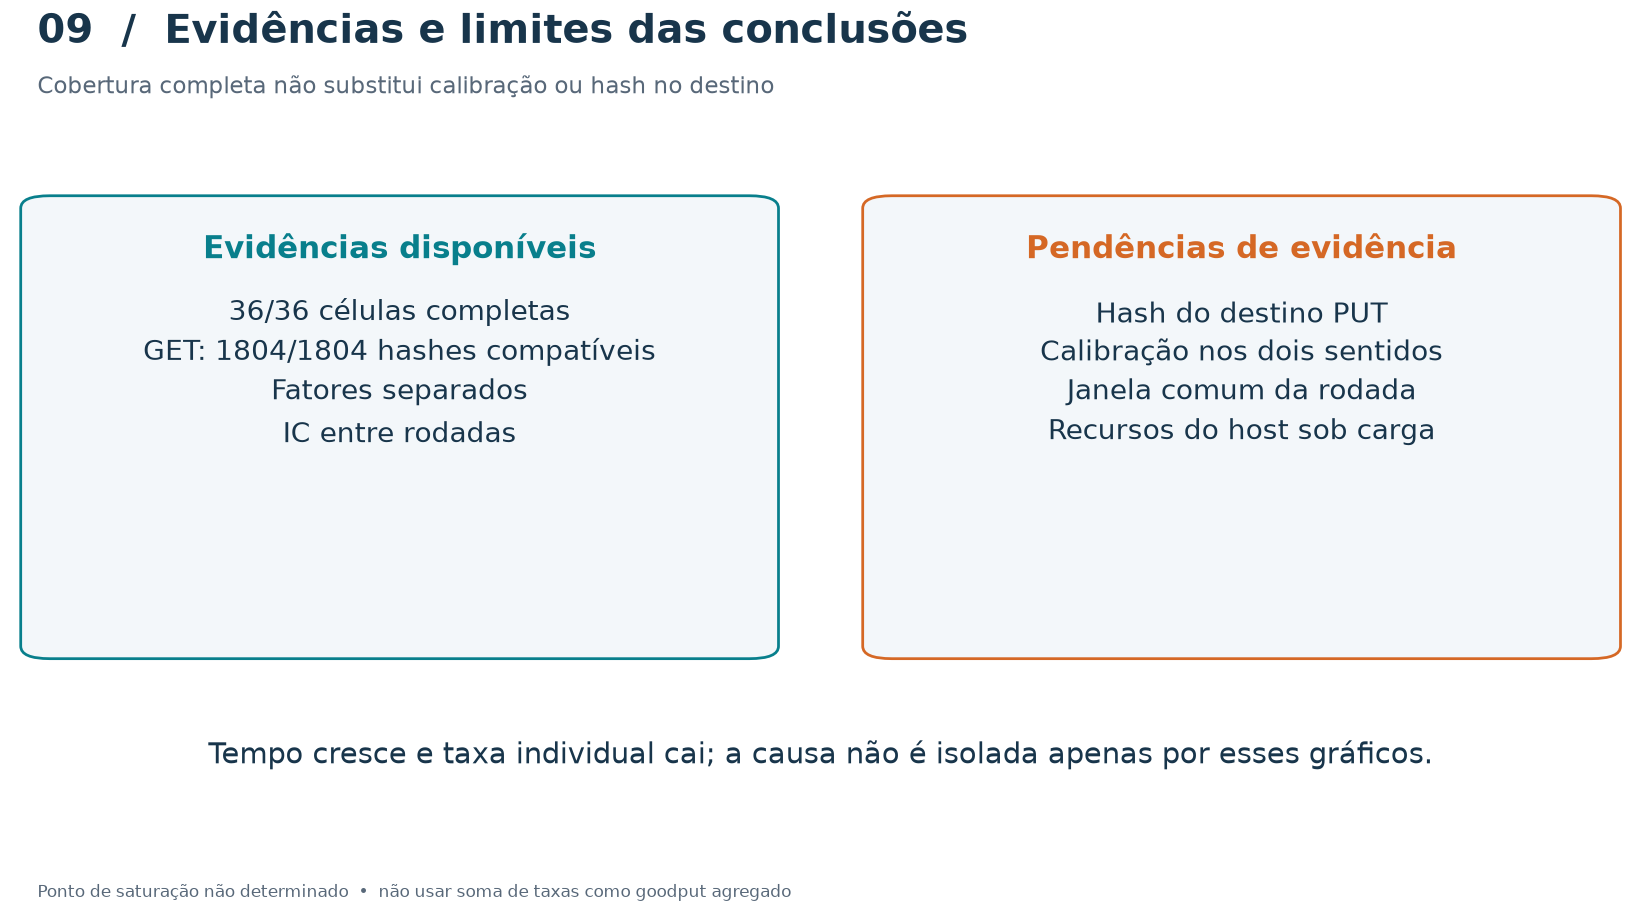

In [22]:
get_part=req.loc[req.operation.eq('GET')]; put_part=req.loc[req.operation.eq('PUT')]
get_checked=int(get_part.hash_evidence.eq('conferido no registro').sum())
put_unchecked=int(put_part.hash_evidence.eq('destino não verificado').sum())
evidence_table=pd.DataFrame([
    {'Item':'Células com rodadas completas','Registro':f'{int(coverage.enough_rounds.sum())}/{len(PLAN)}'},
    {'Item':'GET: hashes iguais preservados','Registro':f'{get_checked}/{len(get_part)}'},
    {'Item':'PUT: destino não verificado','Registro':f'{put_unchecked}/{len(put_part)}'},
    {'Item':'Arquivos de calibração não vazios','Registro':f'{int(calibration.nonempty.sum())}/{len(calibration)}'},
    {'Item':'Janela comum medida da rodada','Registro':'ausente' if rounds.aggregate_mbps.isna().all() else 'revisar schema'}])
csv_slide(9,'evidencias.csv',evidence_table,'Inventário de evidências e pendências')
csv_slide(9,'calibracao_inventario.csv',calibration,'Existência e tamanho dos arquivos esperados de calibração')
fig,ax=tela(9,'Evidências e limites das conclusões','Cobertura completa não substitui calibração ou hash no destino',
            'Ponto de saturação não determinado  •  não usar soma de taxas como goodput agregado')
caixa(ax,.015,.26,.45,.65,'Evidências disponíveis',f'{int(coverage.enough_rounds.sum())}/{len(PLAN)} células completas\n'
      f'GET: {get_checked}/{len(get_part)} hashes compatíveis\nFatores separados\nIC entre rodadas',wrap=39,fonte=20)
caixa(ax,.535,.26,.45,.65,'Pendências de evidência','Hash do destino PUT\nCalibração nos dois sentidos\n'
      'Janela comum da rodada\nRecursos do host sob carga',cor=LARANJA,wrap=39,fonte=20)
ax.text(.5,.10,'Tempo cresce e taxa individual cai; a causa não é isolada apenas por esses gráficos.',ha='center',fontsize=19,color=AZUL)
salvar_visual(fig,9,'evidencias_limites','Evidências disponíveis e limitações experimentais')
instrucoes_slide(9,'Inserir evidencias_limites.png. Os CSVs sustentam o quadro. Não inventar gráficos de ping, '
                    'iperf, CPU ou vazão agregada. Uma nova coleta deve preservar calibração, hash do destino PUT e '
                    'início/fim monotônicos comuns da rodada; o notebook não cria essas evidências retroativamente.')

## Slide 10 — Contribuições · 7:25–8:20

Gera a divisão do roteiro marcada como **proposta** enquanto `CONTRIBUICOES_CONFIRMADAS=False`. Edite nomes e responsabilidades conforme a participação real antes de confirmar.

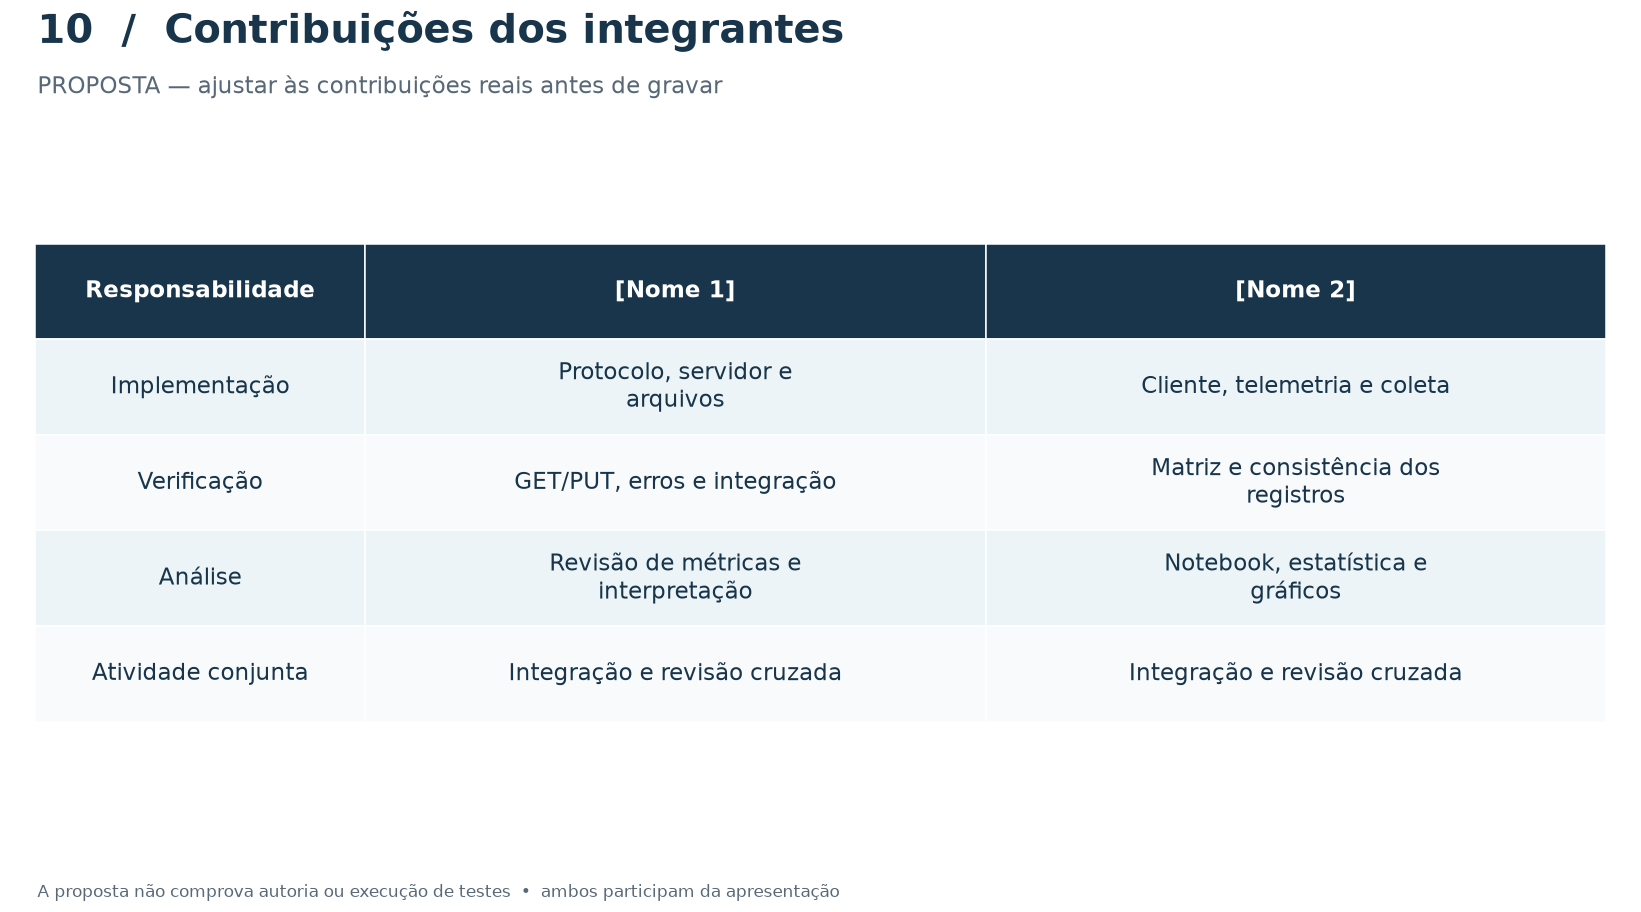

In [23]:
assert NOMES[0]!=NOMES[1],'Use nomes distintos para as duas colunas.'
contrib=pd.DataFrame([
    {'Responsabilidade':'Implementação',NOMES[0]:'Protocolo, servidor e arquivos',NOMES[1]:'Cliente, telemetria e coleta'},
    {'Responsabilidade':'Verificação',NOMES[0]:'GET/PUT, erros e integração',NOMES[1]:'Matriz e consistência dos registros'},
    {'Responsabilidade':'Análise',NOMES[0]:'Revisão de métricas e interpretação',NOMES[1]:'Notebook, estatística e gráficos'},
    {'Responsabilidade':'Atividade conjunta',NOMES[0]:'Integração e revisão cruzada',NOMES[1]:'Integração e revisão cruzada'}])
csv_slide(10,'contribuicoes.csv',contrib,'Divisão a revisar conforme a participação real')
contrib_view=contrib.map(lambda x:textwrap.fill(str(x),29))
status_contrib='Contribuições confirmadas pelos integrantes' if CONTRIBUICOES_CONFIRMADAS else 'PROPOSTA — ajustar às contribuições reais antes de gravar'
tabela_visual(10,'contribuicoes',contrib_view,'Contribuições dos integrantes',status_contrib,
               'A proposta não comprova autoria ou execução de testes  •  ambos participam da apresentação',larguras=[.21,.395,.395])
instrucoes_slide(10,'Revisar os nomes e cada responsabilidade nesta célula. Só então definir '
                     'CONTRIBUICOES_CONFIRMADAS=True e regenerar. Usar contribuicoes.png ou o CSV para uma tabela '
                     'editável. O marcador PROPOSTA é intencional enquanto a participação não foi confirmada.')

## Slide 11 — Autoavaliação e conclusão · 8:20–9:40

Gera três blocos de autoavaliação sugerida e síntese calculada de A/B. A fala final precisa ser revisada pelos integrantes. Não atribui nota nem certifica cumprimento integral dos requisitos.

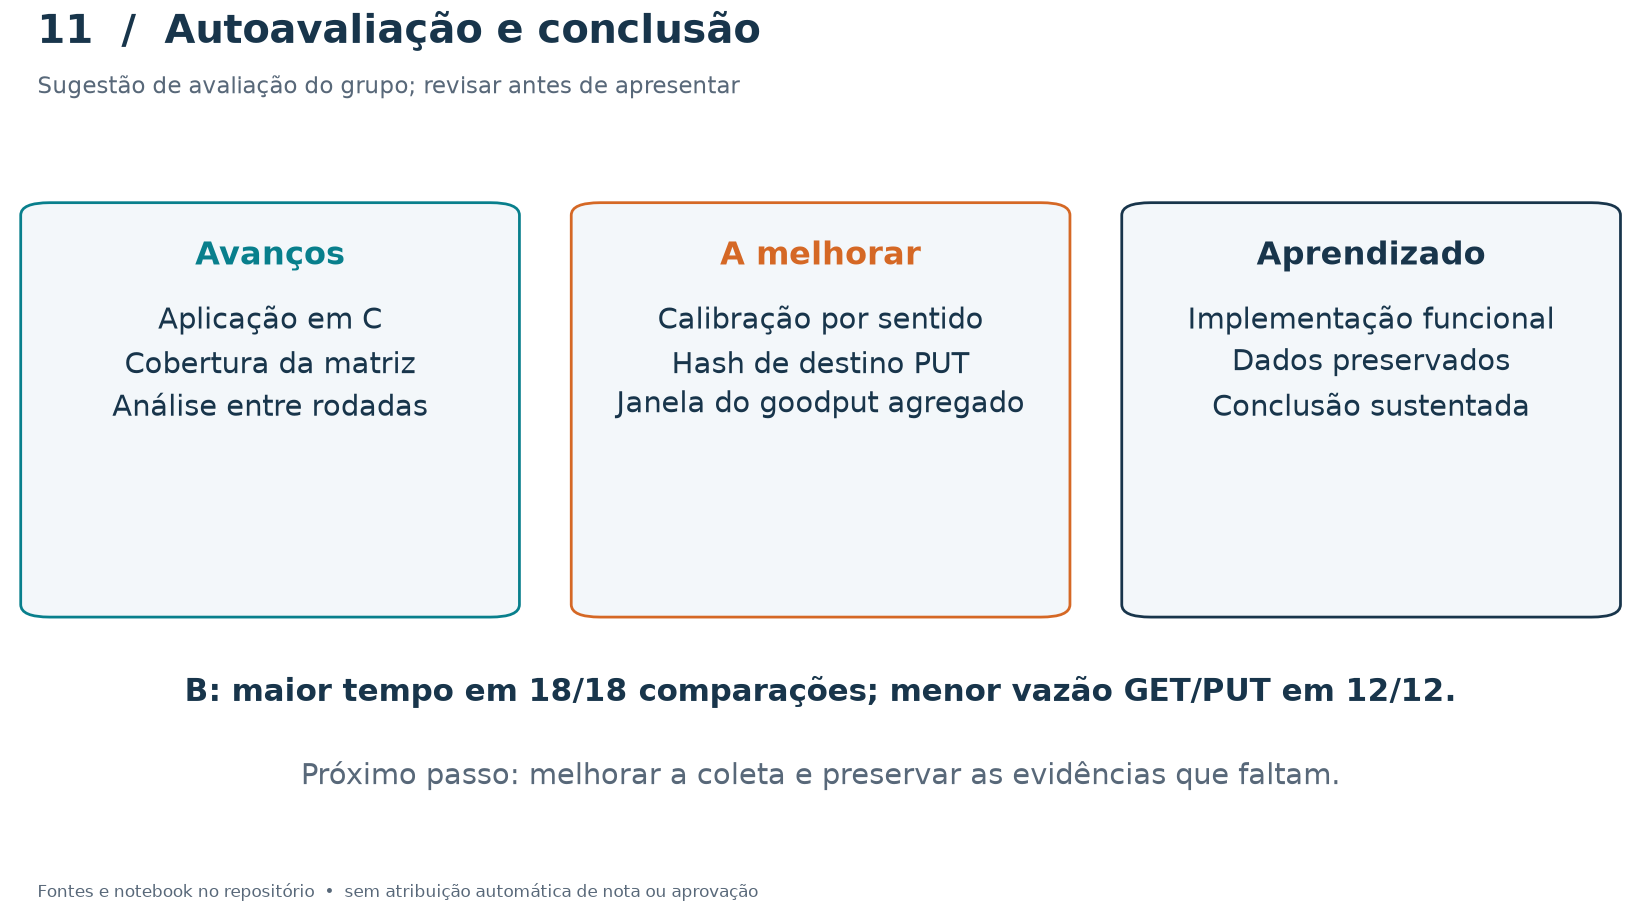

In [24]:
lat_slide=comparison.loc[comparison.metric.eq('response_ms')]
rate_slide=comparison.loc[comparison.metric.eq('individual_mbps')&comparison.operation.ne('HEAD')]
conclusions=pd.DataFrame([
    {'Resultado':'B com maior tempo','Comparações':f'{int((lat_slide.B>lat_slide.A).sum())}/{len(lat_slide)}'},
    {'Resultado':'B com menor vazão individual GET/PUT','Comparações':f'{int((rate_slide.B<rate_slide.A).sum())}/{len(rate_slide)}'},
    {'Resultado':'Ponto de saturação','Comparações':'não determinado'}])
csv_slide(11,'conclusoes.csv',conclusions,'Síntese calculada e limite da avaliação de saturação')
fig,ax=tela(11,'Autoavaliação e conclusão','Sugestão de avaliação do grupo; revisar antes de apresentar',
            'Fontes e notebook no repositório  •  sem atribuição automática de nota ou aprovação')
for x,title,body,cor in [(.015,'Avanços','Aplicação em C\nCobertura da matriz\nAnálise entre rodadas',VERDE),
                         (.355,'A melhorar','Calibração por sentido\nHash de destino PUT\nJanela do goodput agregado',LARANJA),
                         (.695,'Aprendizado','Implementação funcional\nDados preservados\nConclusão sustentada',AZUL)]:
    caixa(ax,x,.32,.29,.58,title,body,cor=cor,fonte=21,wrap=26)
ax.text(.5,.19,f'B: maior tempo em {int((lat_slide.B>lat_slide.A).sum())}/{len(lat_slide)} comparações; '
        f'menor vazão GET/PUT em {int((rate_slide.B<rate_slide.A).sum())}/{len(rate_slide)}.',
        ha='center',fontsize=20,color=AZUL,weight='bold')
ax.text(.5,.07,'Próximo passo: melhorar a coleta e preservar as evidências que faltam.',ha='center',fontsize=19,color=CINZA)
salvar_visual(fig,11,'autoavaliacao_conclusao','Autoavaliação sugerida e resultados observados')
instrucoes_slide(11,'Usar autoavaliacao_conclusao.png e adaptar a fala à avaliação real do grupo. Não chamar '
                     'o trabalho de integralmente validado. Ensaiar com pausas e transições; o roteiro prevê '
                     '9min40s e 20 segundos de margem. Os integrantes gravam a narração e o vídeo separadamente.')

## Índice, fontes e conferência dos arquivos gerados

O índice relaciona os materiais aos slides; o manifesto registra hashes dos arquivos exportados. `fontes_json.csv` identifica os dados brutos e `proveniencia.json` registra matriz, roteiro, XMLs, versão do código e bibliotecas. Arquivos manuais de gravação não são apagados nem apresentados como evidência gerada.

In [25]:
csv_slide(0,'fontes_json.csv',manifest,'SHA-256 dos JSONs usados na análise')
extra_sources=xml_sources+[{'path':str(p.relative_to(ROOT)),'sha256':hashlib.sha256(p.read_bytes()).hexdigest()}
                           for p in [ROOT/'configs/experiment_plan.csv',ROTEIRO_PATH]]
nb_path=ROOT/'analysis/analise_resultados.ipynb'
nb_sources=[c['source'] for c in json.loads(nb_path.read_text())['cells']]
proveniencia_slides={
    'gerado_utc':dt.datetime.now(dt.timezone.utc).isoformat(),'raw':str(RAW.relative_to(ROOT)),
    'fontes_extras':extra_sources,
    'notebook_fontes_sha256':hashlib.sha256(json.dumps(nb_sources,ensure_ascii=False,sort_keys=True).encode()).hexdigest(),
    'git_head':subprocess.check_output(['git','rev-parse','HEAD'],cwd=ROOT,text=True).strip(),
    'python':platform.python_version(),
    'bibliotecas':{m:importlib.metadata.version(m) for m in ['numpy','pandas','scipy','matplotlib']},
    'contribuicoes_confirmadas':CONTRIBUICOES_CONFIRMADAS,
    'limites':['Sem nova execução CORE','Sem vídeo gerado','Sem comprovação remota de PUT',
              'Sem janela medida para goodput agregado','Calibração inventariada, não aprovada']}
texto_slide(0,'proveniencia.json',json.dumps(proveniencia_slides,ensure_ascii=False,indent=2),'Fontes e ambiente da geração')
index=pd.DataFrame(ARQUIVOS_SLIDES)
assert set(index.loc[index.slide.gt(0),'slide'])==set(range(1,12))
assert not index.arquivo.duplicated().any(),'Nome repetido na geração'
readme=['# Materiais dos slides','','Gerados pela seção final de `analysis/analise_resultados.ipynb`, '
        'seguindo `analysis/reports/roteiro_video.md`.','',
        'Execute todas as células com o venv de análise. Geração ativada por padrão e independente da exportação '
        'opcional da análise. PNG: 2560×1440; SVG: vetorial editável; CSV: dados exatos; '
        'INSTRUCOES.md: conteúdo/fala e tarefas manuais. Reexecutar atualiza arquivos gerados sem apagar vídeos manuais.','',
        '**A completar:** nomes e contribuições reais; gravação da demonstração; montagem; narração e vídeo. '
        'Diagramas são esquemas do código/XML, não capturas de execução. Não há dados fabricados de calibração, '
        'PUT remoto ou vazão agregada.','',
        '| Slide | Arquivo | Conteúdo |','| --- | --- | --- |']
for row in index.itertuples():
    readme.append(f'| {row.slide or "Fontes"} | [{row.arquivo}]({row.arquivo}) | {row.conteudo} |')
texto_slide(0,'README.md','\n'.join(readme),'Índice e orientações gerais')
index=pd.DataFrame(ARQUIVOS_SLIDES)
csv_slide(0,'indice.csv',index,'Índice tabular dos arquivos produzidos')
if GERAR_ARQUIVOS_SLIDES:
    artifact_manifest=[]
    for row in ARQUIVOS_SLIDES:
        dest=SLIDES/row['arquivo']
        assert dest.is_file() and dest.stat().st_size>0,f'Arquivo ausente: {dest}'
        artifact_manifest.append({**row,'bytes':dest.stat().st_size,'sha256':hashlib.sha256(dest.read_bytes()).hexdigest()})
    (SLIDES/'manifesto_arquivos.csv').write_text(pd.DataFrame(artifact_manifest).to_csv(index=False),encoding='utf-8')
    print(f'{len(artifact_manifest)} arquivos gerados + manifesto_arquivos.csv em {SLIDES}')
else:
    print('Apenas prévias exibidas; gravação desativada.')
display(pd.DataFrame(ARQUIVOS_SLIDES).groupby('slide').size().rename('arquivos').reset_index())

64 arquivos gerados + manifesto_arquivos.csv em /home/ember/projetos/Trabalho1-Redes/analysis/slides


,slide,arquivos
0,0,4
1,1,3
2,2,4
3,3,6
4,4,4
5,5,5
6,6,9
7,7,10
8,8,6
9,9,5
